In [456]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

| **Field**           | **Description**                                                                      |
| ------------------- | ------------------------------------------------------------------------------------ |
| **name**            | The full name of the vehicle, including make, model, and trim.                       |
| **description**     | A brief description of the vehicle, often including key features and selling points. |
| **make**            | The manufacturer of the vehicle (e.g., Ford, Toyota, BMW).                           |
| **model**           | The model name of the vehicle.                                                       |
| **year**            | The year the vehicle was manufactured.                                               |
| **price**           | The price of the vehicle in USD.                                                     |
| **engine**          | Details about the engine, including type and specifications.                         |
| **cylinders**       | The number of cylinders in the vehicle's engine.                                     |
| **fuel**            | The type of fuel used by the vehicle (e.g., Gasoline, Diesel, Electric).             |
| **mileage**         | The mileage of the vehicle, typically in miles.                                      |
| **transmission**    | The type of transmission (e.g., Automatic, Manual).                                  |
| **trim**            | The trim level of the vehicle, indicating different feature sets or packages.        |
| **body**            | The body style of the vehicle (e.g., SUV, Sedan, Pickup Truck).                      |
| **doors**           | The number of doors on the vehicle.                                                  |
| **exterior\_color** | The exterior color of the vehicle.                                                   |
| **interior\_color** | The interior color of the vehicle.                                                   |
| **drivetrain**      | The drivetrain of the vehicle (e.g., All-wheel Drive, Front-wheel Drive).            |

In [457]:
path = "/kaggle/input/datasets/mostafa3twa/vehicle-price-dataset/Vehicle Price - Vehicle Price.csv"
if not os.path.exists(path):
    path = "data/Vehicle Price - Vehicle Price.csv"

df = pd.read_csv(path)

In [458]:
df.duplicated().sum()

np.int64(24)

In [459]:
df.drop_duplicates(inplace=True)

In [460]:
df.duplicated().sum()

np.int64(0)

In [461]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 978 entries, 0 to 1001
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   name            978 non-null    object 
 1   description     926 non-null    object 
 2   make            978 non-null    object 
 3   model           978 non-null    object 
 4   year            978 non-null    int64  
 5   price           955 non-null    float64
 6   engine          976 non-null    object 
 7   cylinders       875 non-null    float64
 8   fuel            971 non-null    object 
 9   mileage         946 non-null    float64
 10  transmission    976 non-null    object 
 11  trim            977 non-null    object 
 12  body            975 non-null    object 
 13  doors           971 non-null    float64
 14  exterior_color  973 non-null    object 
 15  interior_color  940 non-null    object 
 16  drivetrain      978 non-null    object 
dtypes: float64(4), int64(1), object(12)
mem

In [462]:
df.isnull().sum().sort_values(ascending=False)
#df.isnull().sum().sort_values(ascending=False)*100/(len(data))

cylinders         103
description        52
interior_color     38
mileage            32
price              23
fuel                7
doors               7
exterior_color      5
body                3
engine              2
transmission        2
trim                1
name                0
model               0
make                0
year                0
drivetrain          0
dtype: int64

## Handling Nulls

### mileage

In [463]:
df['mileage'].value_counts()

mileage
5.0      116
10.0     107
0.0      105
1.0       56
6.0       50
        ... 
697.0      1
66.0       1
41.0       1
141.0      1
296.0      1
Name: count, Length: 95, dtype: int64

In [464]:
#pd.set_option('display.max_rows', None)

In [465]:
def plot_hist_and_box(column_data, column_name=None):
    """
    Plots a histogram and a boxplot side by side for a given pandas Series.

    Args:
        column_data (pd.Series): The data column to plot (e.g., data['cylinders']).
        column_name (str, optional): The name of the column for labeling. If None, uses Series name.
    """
    if column_name is None:
        column_name = column_data.name

    plt.figure(figsize=(12, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(column_data, kde=True, bins=20, color='skyblue')
    plt.title(f'Histogram of {column_name}')
    plt.xlabel(column_name)
    plt.ylabel('Frequency')

    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=column_data, color='lightgreen')
    plt.title(f'Boxplot of {column_name}')
    plt.xlabel(column_name)

    plt.tight_layout()
    plt.show()

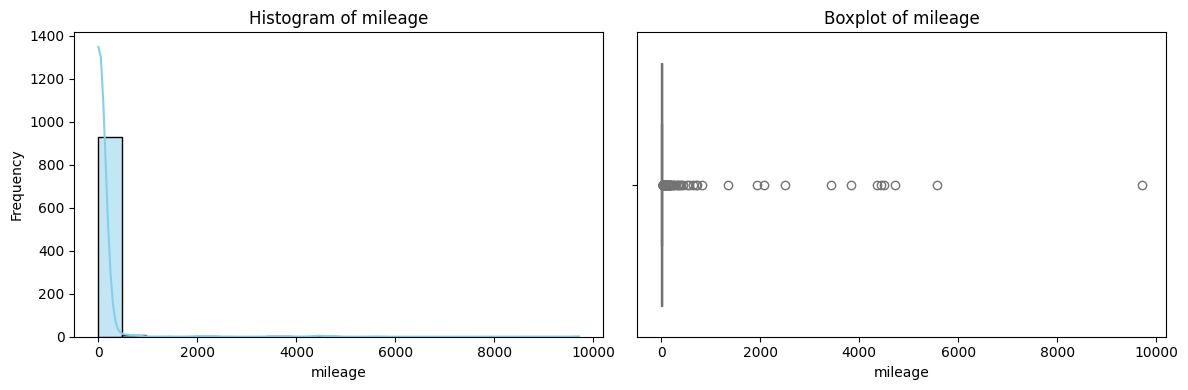

In [466]:
plot_hist_and_box(df['mileage'])

In [467]:
df['mileage'].describe()

count     946.000000
mean       70.359408
std       513.229062
min         0.000000
25%         4.000000
50%         8.000000
75%        13.000000
max      9711.000000
Name: mileage, dtype: float64

### 🧠 Basic Info for Handling Null Values in Numerical Data

As basic info, to impute or fill null values for **numerical/continuous data**, we usually use the **mean** or **median**. 📊

According to the previous info about the column:

* 📈 The data is **right-skewed**
* ⚠️ There are **many outliers**

👉 So, in this case, it's better to **fill null values with the *median***. ✅

In [468]:
df['mileage'] = df['mileage'].fillna(df['mileage'].median())

In [469]:
df['mileage'].isnull().sum()

np.int64(0)

### price

In [470]:
df['price'].describe()

count       955.000000
mean      50314.982199
std       18795.326296
min           0.000000
25%       36772.000000
50%       47234.000000
75%       59076.500000
max      195895.000000
Name: price, dtype: float64

In [471]:
df[df["price"]==0]

,name,description,make,model,year,price,engine,cylinders,fuel,mileage,transmission,trim,body,doors,exterior_color,interior_color,drivetrain
94,2024 Audi SQ5 Premium Plus,\n \n Ultra Blue Metallic 2024 Aud...,Audi,SQ5,2024,0.0,oled Turbo Premium Unleaded V-6 3.0 L/183,6.0,Gasoline,14.0,Automatic,Premium Plus,SUV,4.0,Ultra Blue Metallic,Black,All-wheel Drive


In [472]:
df = df[df['price'] != 0]

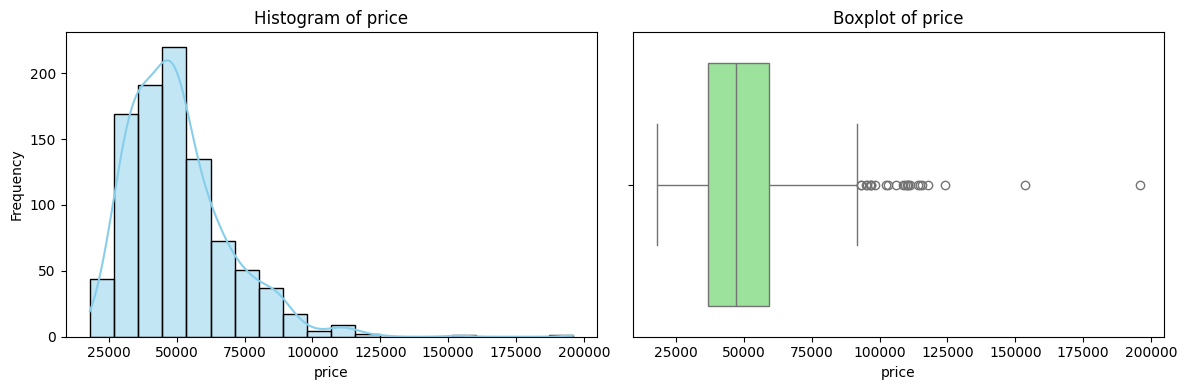

In [473]:
plot_hist_and_box(df['price'])

In [474]:
df['price'].isnull().sum()

np.int64(23)

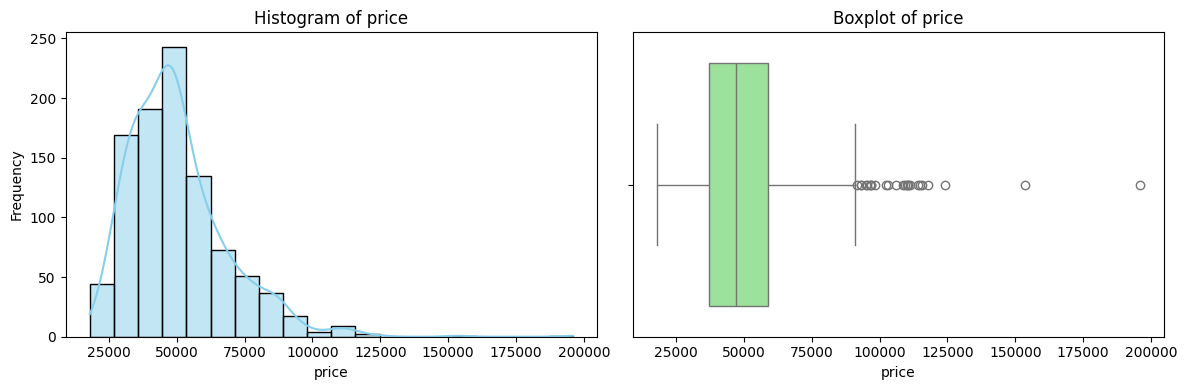

In [475]:
plot_hist_and_box(df['price'].fillna(df['price'].median()))

### 🧠 General Scenario for Handling Missing Values

In a general scenario, we will **fill missing values with the *median*** because of the presence of **outliers**. ⚠️
The **mean** is affected by outliers, while the **median is robust** — it represents the “middle” value, regardless of how extreme the outliers are. 📈✅

---

### 🚗 In Our Case (Price Column)

However, in our case (the **`price`** column), I will **drop these null values** ❌ because this is our **target column**. 🎯
Later, we will **predict the car price** based on its information. 🧾🔮

In [476]:
df.shape
#len(data)

(977, 17)

In [477]:
data = df.dropna(subset=['price'])

In [478]:
data['price'].isnull().sum()

np.int64(0)

In [479]:
len(data)

954

### fuel

In [480]:
data['fuel'].value_counts()

fuel
Gasoline                626
Hybrid                  134
Electric                 94
Diesel                   72
PHEV Hybrid Fuel         15
E85 Flex Fuel             5
Diesel (B20 capable)      1
Name: count, dtype: int64

In [481]:
data['fuel'].isnull().sum()

np.int64(7)

In [482]:
data['fuel'].mode()

0    Gasoline
Name: fuel, dtype: object

In [483]:
import warnings
warnings.filterwarnings('ignore')

In [484]:
data['fuel'] = data['fuel'].fillna(data['fuel'].mode()[0])

### ⛽ Fuel Column (Categorical)

The **`fuel`** column is **categorical**, so we can fill the **NaN values** with the **mode** (the most frequent value). 📊✅

In [485]:
data.isnull().sum().sort_values(ascending=False)

cylinders         100
description        52
interior_color     37
doors               7
exterior_color      5
body                3
engine              2
transmission        2
trim                1
name                0
fuel                0
model               0
year                0
make                0
price               0
mileage             0
drivetrain          0
dtype: int64

### cylinders

In [486]:
data['cylinders'].value_counts()

cylinders
4.0    479
6.0    266
8.0     81
3.0     26
0.0      2
Name: count, dtype: int64

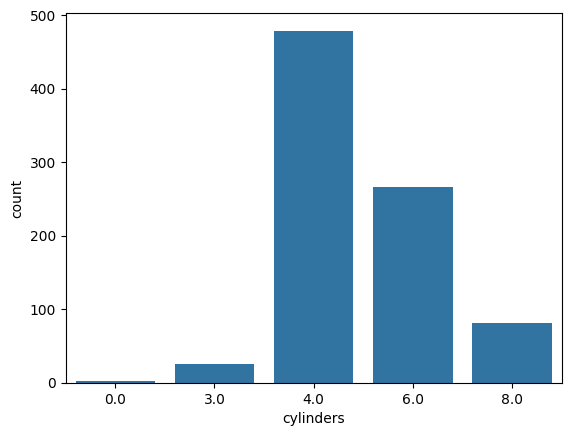

In [487]:
sns.countplot(data = data, x = 'cylinders');

In [488]:
data.groupby('make')['cylinders'].value_counts().to_frame()

count
make          cylinders       
Acura         6.0           11
              0.0            1
Audi          4.0            8
BMW           6.0            5
              4.0            2
              8.0            1
Buick         3.0            4
              4.0            2
              6.0            1
Cadillac      4.0            4
              6.0            1
Chevrolet     8.0           19
              4.0           17
              6.0            5
              3.0            2
Chrysler      6.0           10
Dodge         4.0           59
              8.0           32
              6.0           10
Ford          6.0           25
              4.0           24
              3.0           16
              8.0            3
GMC           8.0           11
              4.0            6
              6.0            3
Honda         4.0           10
              6.0            6
Hyundai       4.0           85
              6.0            2
INFINITI      4.0            5
Jeep          6.0           96
              4.0           94
Kia           4.0           40
              6.0            1
Land Rover    4.0            3
              6.0            1
Lexus         4.0            1
Lincoln       4.0            2
Mazda         4.0           33
              6.0            3
Mercedes-Benz 4.0           12
              6.0            6
Nissan        4.0           23
              6.0            8
              8.0            5
              3.0            4
RAM           6.0           67
              8.0           10
Subaru        4.0            7
Toyota        6.0            5
              4.0            3
Volkswagen    4.0           37
Volvo         4.0            2
              0.0            1

In [489]:
data.groupby('make')['cylinders'].value_counts().reset_index(name='count')

,make,cylinders,count
0,Acura,6.0,11
1,Acura,0.0,1
2,Audi,4.0,8
3,BMW,6.0,5
4,BMW,4.0,2
5,BMW,8.0,1
6,Buick,3.0,4
7,Buick,4.0,2
8,Buick,6.0,1
9,Cadillac,4.0,4


In [490]:
pd.crosstab(data['make'], data['cylinders'])

cylinders,0.0,3.0,4.0,6.0,8.0
make,,,,,
Acura,1,0,0,11,0
Audi,0,0,8,0,0
BMW,0,0,2,5,1
Buick,0,4,2,1,0
Cadillac,0,0,4,1,0
Chevrolet,0,2,17,5,19
Chrysler,0,0,0,10,0
Dodge,0,0,59,10,32
Ford,0,16,24,25,3


In [491]:
cylinder_mode_per_make = data.groupby('make')['cylinders'].apply(lambda x: x.mode()).droplevel(level=None).to_dict()
# droplevel() removes the extra index level created after groupby and apply.
cylinder_mode_per_make

{'Acura': 6.0,
 'Audi': 4.0,
 'BMW': 6.0,
 'Buick': 3.0,
 'Cadillac': 4.0,
 'Chevrolet': 8.0,
 'Chrysler': 6.0,
 'Dodge': 4.0,
 'Ford': 6.0,
 'GMC': 8.0,
 'Honda': 4.0,
 'Hyundai': 4.0,
 'INFINITI': 4.0,
 'Jeep': 6.0,
 'Kia': 4.0,
 'Land Rover': 4.0,
 'Lexus': 4.0,
 'Lincoln': 4.0,
 'Mazda': 4.0,
 'Mercedes-Benz': 4.0,
 'Nissan': 4.0,
 'RAM': 6.0,
 'Subaru': 4.0,
 'Toyota': 6.0,
 'Volkswagen': 4.0,
 'Volvo': 4.0}

In [492]:
data['cylinders'] = data['cylinders'].fillna(data['make'].map(cylinder_mode_per_make))

In [493]:
data.isnull().sum()

name               0
description       52
make               0
model              0
year               0
price              0
engine             2
cylinders          3
fuel               0
mileage            0
transmission       2
trim               1
body               3
doors              7
exterior_color     5
interior_color    37
drivetrain         0
dtype: int64

In [494]:
cylinder_mode = data['cylinders'].mode()[0]  # global mode
cylinder_mode

np.float64(4.0)

In [495]:
data['cylinders'] = data['cylinders'].fillna(data['make'].map(cylinder_mode_per_make)).fillna(4)

In [496]:
"""
def fill_missing_cylinders(row):
    if pd.isnull(row['cylinders']):
        return cylinder_mode_per_make.get(row['make'], cylinder_mode)
    else:
        return row['cylinders']
"""

"\ndef fill_missing_cylinders(row):\n    if pd.isnull(row['cylinders']):\n        return cylinder_mode_per_make.get(row['make'], cylinder_mode)\n    else:\n        return row['cylinders']\n"

In [497]:
#data['cylinders'] = data.apply(fill_missing_cylinders, axis=1)

In [498]:
data['cylinders'].isnull().sum()

np.int64(0)

### 🧩 General Strategy for Filling Missing Categorical Values

In general, we can fill **missing values** in **categorical columns** using the **mode** (most frequent value) 🏷️✅
Or, we can fill them based on the values in **another related column**.

🔍 For example, in our case, we can **filled the `cylinders` column** based on the **`make` of the car**. 🚗🔧

In [499]:
data.isnull().sum().sort_values(ascending=False)

description       52
interior_color    37
doors              7
exterior_color     5
body               3
transmission       2
engine             2
trim               1
name               0
fuel               0
cylinders          0
price              0
year               0
make               0
model              0
mileage            0
drivetrain         0
dtype: int64

### interior_color

In [500]:
data['interior_color'].mode()

0    Black
Name: interior_color, dtype: object

In [501]:
data['interior_color'].unique()

array(['Global Black', 'Teak/Light Shale', 'Black', 'Gray', 'Black Onyx',
       'Dark Gray', 'Beige', 'Ebony', 'Black Cloud', 'Titan Black',
       'Jet Blk', 'Graphite', 'Dark Palazzo Gray', 'Jet Black',
       'Jet Blk Premium Clth', 'Diesel Gray/Black', nan, 'Pearl Beige',
       'Beige / Black', 'Cognac', 'Charcoal', 'Black Interior Color',
       'Steel Gry Premium Cl', 'Medium Ash Gray', 'Greige', 'White',
       'Pebble Gray', 'Medium Earth Gray', 'Jet Black w/Red Accents',
       'Tacora Red', 'Ebony Black', 'Ebony/Roast', 'Medium Gray',
       'Mauro Brown', 'Nutmeg', 'Ruby Red', 'Gideon/Very Dark Atmosphere',
       'Dark Walnut / Slate', 'Okapi Brown', 'Lt Mountain Brown/Brown',
       'Jet Black With Red Accents', 'Gry Lthette', 'Black / Diesel Gray',
       'Sepia / Black', 'Sea Salt', 'Medium Pewter', 'Nh-731p/Black',
       'Dk Palazzo Gry Fron', 'Black/Alloy/Black', 'Griege',
       'Ebony W/Red Stitching', 'Medium Sandstone', 'Dark Green',
       'Brown/Blk', 'Gray / 

In [502]:
data.groupby('make')['interior_color'].unique()

make
Acura                                                        [nan]
Audi                       [Pearl Beige, Black, Okapi Brown, Gray]
BMW              [Cognac, Tacora Red, Black, Oyster, Silverston...
Buick                                     [Ebony, Dark Galvanized]
Cadillac         [Jet Black, Noir w/Santorini Blue Accents, Bla...
Chevrolet        [Black, Jet Black, Medium Ash Gray, Jet Black ...
Chrysler                                [Black, Black/Alloy/Black]
Dodge                                                 [Black, nan]
Ford             [Black Onyx, Ebony, Dark Palazzo Gray, Black, ...
GMC              [Teak/Light Shale, Jet Blk, Jet Blk Premium Cl...
Genesis                                                    [Black]
Honda            [Black, Gray, Beige, Nh-731p/Black, nan, Nh-79...
Hyundai          [Black, Dark Gray, Gray, Medium Gray, Dark Gre...
INFINITI                       [Pebble Gray, Graphite, Monaco Red]
Jaguar                                                   

In [503]:
data.groupby('make')['interior_color'].apply(lambda x: x.mode()).droplevel(level=None).to_dict()

{'Audi': 'Black',
 'BMW': 'Black',
 'Buick': 'Ebony',
 'Cadillac': 'Jet Black',
 'Chevrolet': 'Jet Black',
 'Chrysler': 'Black',
 'Dodge': 'Black',
 'Ford': 'Ebony',
 'GMC': 'Jet Black',
 'Genesis': 'Black',
 'Honda': 'Black',
 'Hyundai': 'Black',
 'INFINITI': 'Pebble Gray',
 'Jaguar': 'Ebony',
 'Jeep': 'Black',
 'Kia': 'Black',
 'Land Rover': 'Gray',
 'Lexus': 'Black',
 'Lincoln': 'Ebony',
 'Mazda': 'Black',
 'Mercedes-Benz': 'Black',
 'Nissan': 'Charcoal',
 'RAM': 'Black',
 'Subaru': 'Black',
 'Toyota': 'Black',
 'Volkswagen': 'Black',
 'Volvo': 'Charcoal'}

### 🎨 Handling Missing Values in the `interior_color` Column
Color has low influence on price
We can see that **most cars have the color black**, so we can either:

* ✅ **Fill missing values directly with `"black"`** (the most frequent value),or `'Unknown'`.
  **or**
* 🔄 Use the previous approach and **fill the color based on the car's `make`** (e.g., popular colors for each brand).

In [504]:
data['interior_color'] = data['interior_color'].fillna(data['interior_color'].mode()[0])
data.isnull().sum().sort_values(ascending=False)

description       52
doors              7
exterior_color     5
body               3
transmission       2
engine             2
trim               1
name               0
model              0
fuel               0
cylinders          0
price              0
year               0
make               0
mileage            0
interior_color     0
drivetrain         0
dtype: int64

### doors

In [505]:
data['doors'].value_counts()

doors
4.0    900
3.0     37
2.0      9
5.0      1
Name: count, dtype: int64

In [506]:
data['doors'] = data['doors'].fillna(data['doors'].mode()[0])

### exterior_color
*Note that the number of missing values in exterior_color is very small (5), so we can fill with mode for simplicity*

In [507]:
data['exterior_color'].mode()

0    Bright White Clearcoat
Name: exterior_color, dtype: object

In [508]:
data['exterior_color'] = data['exterior_color'].fillna(data['exterior_color'].mode()[0])

In [509]:
#data.groupby('make')['exterior_color'].unique()

In [510]:
#exterior_color_mode_per_make = (data.groupby('make')['exterior_color'].apply(lambda x: x.mode()).droplevel(level=None).to_dict())
#exterior_color_mode_per_make

In [511]:
#data['exterior_color'] = data['exterior_color'].fillna(data['make'].map(exterior_color_mode_per_make))

In [512]:
data.isnull().sum().sort_values(ascending=False)

description       52
body               3
transmission       2
engine             2
trim               1
name               0
year               0
model              0
make               0
fuel               0
cylinders          0
price              0
mileage            0
doors              0
exterior_color     0
interior_color     0
drivetrain         0
dtype: int64

### other columns

In [513]:
data.columns

Index(['name', 'description', 'make', 'model', 'year', 'price', 'engine',
       'cylinders', 'fuel', 'mileage', 'transmission', 'trim', 'body', 'doors',
       'exterior_color', 'interior_color', 'drivetrain'],
      dtype='object')

In [514]:
data = data.dropna(subset=['transmission', 'trim', 'body','engine'])

In [515]:
data.shape

(946, 17)

In [516]:
# List of target columns to fill with their own mode
#columns_to_fill = ['transmission', 'trim', 'body','engine']

#for col in columns_to_fill:
    #mode_value = data[col].mode(dropna=True)[0]  # get the most frequent non-null value
    #data[col] = data[col].fillna(mode_value)
    #print(f'Filling {col} done...')

#### According to description column

In [517]:
# here are random sample from column
for i in range(5):
    print(data['description'].sample().values[0])


      
        This Mercedes-Benz EQS boasts a Electric engine powering this Automatic transmission. MULTI-CONTOUR FRONT SEATS W/MASSAGE FEATURE, HEATED STEERING WHEEL, HEAD-UP DISPLAY. This Mercedes-Benz EQS Features the Following Options EXCLUSIVE TRIM LEVEL -inc: MBUX Front Interior Assist, Multi-Contour Front Seats w/Massage Feature, AIR BALANCE Package, 4-Zone Climate Control, AMG LINE EXTERIOR PACKAGE -inc: AMG front bumper w/A-Wing in high gloss black w/chrome accents, side skirts in high-gloss black w/chrome accents, chrome rear bumper trim, front splitter in high-gloss chrome and AMG rear bumper w/high-gloss black diffuser insert , Window Grid Diversity Antenna, Wheels: 20 x 8.5J 5-Spoke Aero w/Black Accents, Voice Activated Dual Zone Front Automatic Air Conditioning, Valet Function, Urethane Gear Shifter Material, Turn-By-Turn Navigation Directions, Trunk/Hatch Auto-Latch, Trip Computer. Stop By Today Stop by Mercedes-Benz of Laguna Niguel located at 1 Star Dr, Laguna Niguel

### 📝 Dropping the `description` Column (for Now)

As a beginning, we will **not use the car’s `description`**. ❌🧾
We can consider using it **later** after studying **NLP (Natural Language Processing)** understanding:

* 🧠 How models can **process and understand text**
* 🧹 How to perform **text preprocessing**

So, for now, I will **drop this column**. 🗑️

### 🚘 Dropping the `name` Column

The **`name`** column just refers to the **name of the car**, so it will **not provide useful information** when predicting the **price**. 💰❌

In other words, the **price does not depend** on the name of the car.
So, I will **drop this column as well**. 🗑️

### 🎨 Dropping `exterior_color` and `interior_color` Columns

According to the `exterior_color` and `interior_color` columns, I will **drop them for now** to keep things simple. 🗑️✨

In general, we know that the **color of a product** (like a car) does **not significantly affect its price**. 💡🚗💰

In [518]:
data.drop(columns = ['name', 'description', 'exterior_color', 'interior_color'], inplace=True)

In [519]:
data.head(3)

,make,model,year,price,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain
0,Jeep,Wagoneer,2024,74600.0,24V GDI DOHC Twin Turbo,6.0,Gasoline,10.0,8-Speed Automatic,Series II,SUV,4.0,Four-wheel Drive
1,Jeep,Grand Cherokee,2024,50170.0,OHV,6.0,Gasoline,1.0,8-Speed Automatic,Laredo,SUV,4.0,Four-wheel Drive
2,GMC,Yukon XL,2024,96410.0,"6.2L V-8 gasoline direct injection, variable v...",8.0,Gasoline,0.0,Automatic,Denali,SUV,4.0,Four-wheel Drive


### Summary about filling missing values
| Situation                                                  | Recommended Fill Method                    | Why?                                   |
| ---------------------------------------------------------- | ------------------------------------------ | -------------------------------------- |
| 🔢 Most values are the same (e.g., many 4-cylinder cars)   | `mode()`                                   | Likely that missing ones are the same  |
| 🎯 Data is numeric but has outliers (e.g., 3, 4, 6, 8, 12) | `median()`                                 | Median is robust to outliers           |
| ➗ Data is numeric and fairly normally distributed          | `mean()`                                   | Mean gives a good central estimate     |
| ⏱️ Data is ordered (e.g., time-based car listings)         | `ffill()` or `bfill()`                     | Use context from nearby rows           |
| 📈 Data is numeric and smooth or continuous                | `interpolate()`                            | Uses mathematical trend from neighbors |
| 🛑 You want to flag and treat missing data separately      | Fill with `-1` or `'Unknown'`, or add flag | Helps model know this was missing      |

In [520]:
from sklearn.model_selection import train_test_split

In [521]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [522]:
X = data.drop(columns='price')
y = data['price']

In [523]:
import sys
print(sys.executable)

import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

print("All imports successful!")
print("Scikit-learn version:", sklearn.__version__)

/usr/bin/python3
All imports successful!
Scikit-learn version: 1.6.1


In [524]:
X.head(2)

,make,model,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain
0,Jeep,Wagoneer,2024,24V GDI DOHC Twin Turbo,6.0,Gasoline,10.0,8-Speed Automatic,Series II,SUV,4.0,Four-wheel Drive
1,Jeep,Grand Cherokee,2024,OHV,6.0,Gasoline,1.0,8-Speed Automatic,Laredo,SUV,4.0,Four-wheel Drive


In [525]:
y.head(2)

0    74600.0
1    50170.0
Name: price, dtype: float64

In [526]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=32)
print(f'X_train shape : {X_train.shape}')
print(f'X_test shape : {X_test.shape}')

X_train shape : (756, 12)
X_test shape : (190, 12)


In [527]:
X_train.head(3)

,make,model,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain
321,Volkswagen,Jetta,2024,"4 gasoline direct injection, DOHC, variable va...",4.0,Gasoline,7.0,8-Speed Automatic with Tiptronic,1.4T SE,Sedan,4.0,Front-wheel Drive
225,Volkswagen,Taos,2024,16V GDI DOHC Turbo,4.0,Gasoline,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,SUV,4.0,All-wheel Drive
815,Honda,Passport,2024,24V GDI SOHC,6.0,Gasoline,0.0,9-Speed Automatic,TrailSport,SUV,4.0,All-wheel Drive


In [528]:
X_test.head(3)

,make,model,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain
293,BMW,i7,2024,c,6.0,Electric,5.0,1-Speed Automatic,eDrive50,Sedan,4.0,Rear-wheel Drive
276,Mazda,CX-90 PHEV,2024,DOHC 16V LEV3-SULEV30,4.0,PHEV Hybrid Fuel,26.0,Automatic,Premium Plus,SUV,4.0,All-wheel Drive
733,Hyundai,Tucson Hybrid,2024,"ream 1.6L I-4 gasoline direct injection, DOHC,...",4.0,Hybrid,12.0,Automatic,N Line,SUV,4.0,All-wheel Drive


### Encoding

---
one hot encoding
![image.png](attachment:image.png)

-----
label encoding
![image.png](attachment:image.png)

In [529]:
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()
categorical_cols

['make',
 'model',
 'engine',
 'fuel',
 'transmission',
 'trim',
 'body',
 'drivetrain']

In [530]:
for col in categorical_cols:
    print(col)
    print(X_train[col].value_counts())
    print('\n\n')

make
make
Jeep             154
Hyundai           98
Dodge             81
Ford              62
RAM               59
Kia               42
Chevrolet         41
Nissan            31
Volkswagen        28
Mazda             26
Mercedes-Benz     23
Honda             19
BMW               13
Audi              12
GMC               10
Acura             10
Chrysler           9
Cadillac           6
Toyota             6
Buick              6
Subaru             5
INFINITI           4
Land Rover         4
Volvo              2
Lincoln            2
Lexus              1
Jaguar             1
Genesis            1
Name: count, dtype: int64



model
model
Hornet                45
3500                  36
Compass               31
Durango               30
Grand Cherokee 4xe    28
                      ..
QX55                   1
Solterra               1
Transit Connect        1
Enclave                1
740                    1
Name: count, Length: 139, dtype: int64



engine
engine
16V GDI DOHC Turbo            

### 🚘 Features That **Strongly Affect** Price:

| Feature                                    | Affect Price?      | Why                                                                                     |
| ------------------------------------------ | ------------------ | --------------------------------------------------------------------------------------- |
| **make** (e.g., BMW, Toyota)               | ✅ Strongly affects | Brand reputation, reliability, and luxury level play a big role.                        |
| **model** (e.g., Corolla, X5)              | ✅ Strongly affects | Different models within the same brand can have huge price differences.                 |
| **engine** (e.g., 2.0L, V6, hybrid)        | ✅ Strongly affects | Bigger or more advanced engines usually cost more. Fuel economy and performance matter. |
| **fuel** (e.g., petrol, diesel, electric)  | ✅ Affects          | Electric and hybrid cars often cost more upfront. Diesel engines can also raise price.  |
| **transmission** (e.g., manual, automatic) | ✅ Affects          | Automatic is more expensive in many markets; CVT or dual-clutch can also affect price.  |
| **trim** (e.g., SE, Limited, Sport)        | ✅ Strongly affects | Higher trims include more features and comfort, thus higher price.                      |
| **drivetrain** (e.g., FWD, AWD, RWD)       | ✅ Affects          | AWD/4WD is usually more expensive than FWD/RWD, especially in SUVs or off-roaders.      |

---

### 🎨 Features That **May Affect Slightly or Indirectly**:

| Feature                                  | Affect Price?    | Why                                                                        |
| ---------------------------------------- | ---------------- | -------------------------------------------------------------------------- |
| **body** (e.g., sedan, SUV, coupe)       | ⚠️ Medium impact | Some body types are in higher demand or cost more to produce (e.g., SUVs). |
| **exterior\_color** (e.g., red, white)   | ❌ Slight or none | Rarely affects price unless it's a premium/custom color.                   |
| **interior\_color** (e.g., black, beige) | ❌ Slight or none | Only matters in luxury markets or personal preferences.                    |

---

### ✅ Final Summary:

| Feature         | Impact on Price |
| --------------- | --------------- |
| make            | ✅ High          |
| model           | ✅ High          |
| engine          | ✅ High          |
| fuel            | ✅ Medium–High   |
| transmission    | ✅ Medium        |
| trim            | ✅ High          |
| drivetrain      | ✅ Medium        |
| body            | ⚠️ Medium       |
| exterior\_color | ❌ Low           |
| interior\_color | ❌ Low           |

In [531]:
for col in categorical_cols:
    print(col)
    print(X_train[col].unique())
    print('\n\n')

make
['Volkswagen' 'Honda' 'Hyundai' 'Jeep' 'Ford' 'RAM' 'Mercedes-Benz'
 'Mazda' 'Chrysler' 'Audi' 'Nissan' 'Kia' 'Acura' 'Dodge' 'Chevrolet'
 'GMC' 'BMW' 'Volvo' 'Cadillac' 'Lexus' 'Buick' 'Toyota' 'Subaru' 'Jaguar'
 'Lincoln' 'INFINITI' 'Land Rover' 'Genesis']



model
['Jetta' 'Taos' 'Passport' 'IONIQ 5' 'Gladiator' 'Escape' 'Grand Cherokee'
 '3500' 'Sprinter 2500' 'CX-90 PHEV' 'Wrangler' 'Pacifica' 'A3'
 'Mustang Mach-E' 'Grand Cherokee 4xe' 'Atlas' 'Tucson Hybrid' 'Versa'
 'Odyssey' 'Soul' 'MDX' 'Edge' 'Compass' 'Murano' 'Hornet'
 'Silverado 1500' 'RS e-tron GT' 'Telluride' 'Durango' 'Terrain' 'Kona'
 'Wrangler 4xe' 'Titan' 'i4 Gran Coupe' 'ProMaster 2500'
 'Grand Cherokee L' 'GLE 450' 'Altima' 'Wagoneer L' 'Transit-250'
 'Elantra HEV' 'Santa Cruz' 'CR-V' 'Q5 e' 'Maverick' 'Wagoneer' 'Kicks'
 'EV6' 'Bronco Sport' 'XC90 Recharge Plug-In Hybrid' 'A5 Sportback'
 'LYRIQ' 'IONIQ 6' 'ProMaster 1500' 'Sportage' 'Santa Fe' 'Q8 e-tron'
 'ProMaster 3500' 'RX 500h' 'Sonata Hybrid' 'X7' 'Enc

### drivertrain

In [532]:
object_cols = X_train.select_dtypes(include='object').columns.tolist()
print(object_cols)

['make', 'model', 'engine', 'fuel', 'transmission', 'trim', 'body', 'drivetrain']


In [533]:
from sklearn.preprocessing import OneHotEncoder

ohe_drivetrain = OneHotEncoder(sparse_output=False)
encoded_values = ohe_drivetrain.fit_transform(X_train[['drivetrain']])
encoded_values

array([[0., 0., 1., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       ...,
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.]])

In [534]:
encoded_cols = ohe_drivetrain.get_feature_names_out().tolist()
encoded_cols

['drivetrain_All-wheel Drive',
 'drivetrain_Four-wheel Drive',
 'drivetrain_Front-wheel Drive',
 'drivetrain_Rear-wheel Drive']

In [535]:
encoded_df = pd.DataFrame(columns = encoded_cols, data=encoded_values, index=X_train.index)
encoded_df

,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive
321,0.0,0.0,1.0,0.0
225,1.0,0.0,0.0,0.0
815,1.0,0.0,0.0,0.0
630,1.0,0.0,0.0,0.0
445,0.0,1.0,0.0,0.0
...,...,...,...,...
947,0.0,1.0,0.0,0.0
320,1.0,0.0,0.0,0.0
956,1.0,0.0,0.0,0.0
586,1.0,0.0,0.0,0.0


In [536]:
X_train = pd.concat([X_train, encoded_df], axis=1)
X_train

,make,model,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive
321,Volkswagen,Jetta,2024,"4 gasoline direct injection, DOHC, variable va...",4.0,Gasoline,7.0,8-Speed Automatic with Tiptronic,1.4T SE,Sedan,4.0,Front-wheel Drive,0.0,0.0,1.0,0.0
225,Volkswagen,Taos,2024,16V GDI DOHC Turbo,4.0,Gasoline,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,SUV,4.0,All-wheel Drive,1.0,0.0,0.0,0.0
815,Honda,Passport,2024,24V GDI SOHC,6.0,Gasoline,0.0,9-Speed Automatic,TrailSport,SUV,4.0,All-wheel Drive,1.0,0.0,0.0,0.0
630,Hyundai,IONIQ 5,2024,c,4.0,Electric,0.0,Automatic,SEL,SUV,4.0,All-wheel Drive,1.0,0.0,0.0,0.0
445,Jeep,Gladiator,2024,24V MPFI DOHC,6.0,Gasoline,12.0,Automatic,Sport,Pickup Truck,4.0,Four-wheel Drive,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
947,Jeep,Grand Cherokee 4xe,2024,16V GDI DOHC Turbo Hybrid,4.0,Hybrid,11.0,8-Speed Automatic,Base,SUV,4.0,Four-wheel Drive,0.0,1.0,0.0,0.0
320,Audi,Q5 e,2024,"gasoline direct injection, DOHC, variable valv...",4.0,Gasoline,12.0,7-Speed Automatic S tronic,Premium 55 TFSI e S line quattro S tronic,SUV,4.0,All-wheel Drive,1.0,0.0,0.0,0.0
956,Dodge,Hornet,2024,16V GDI DOHC Turbo Hybrid,4.0,Hybrid,5.0,6-Speed Automatic,R/T Plus,SUV,4.0,All-wheel Drive,1.0,0.0,0.0,0.0
586,Ford,Mustang Mach-E,2023,c,6.0,Electric,10.0,1-Speed Automatic,Premium,SUV,4.0,All-wheel Drive,1.0,0.0,0.0,0.0


In [537]:
X_train.drop(columns = ['drivetrain'], inplace=True)
X_train.shape

(756, 15)

### 📌 LabelEncoder vs OrdinalEncoder & When to Use Each
| Feature                | **LabelEncoder**                      | **OrdinalEncoder**                              |
| ---------------------- | ------------------------------------- | ----------------------------------------------- |
| Input                  | **1D vector** (e.g., a single column) | **2D array/DataFrame** (e.g., multiple columns) |
| Output                 | 1D array of integers                  | 2D array of integers                            |
| Use case               | Encode **target variables (labels)**  | Encode **categorical features (input X)**       |
| Handles multiple cols  | ❌ No — only 1 column                  | ✅ Yes                                           |
| Returns ordinal values | ✅ Yes                                 | ✅ Yes                                           |
| Inverse transform      | ✅ Yes                                 | ✅ Yes                                           |
| Commonly used for      | Classification target (`y`)           | Features (`X`) with categories                  |

### 🧠 Key Takeaways
| Use case                                  | Encoder                                  |
| ----------------------------------------- | ---------------------------------------- |
| Encode target variable (`y`)              | `LabelEncoder`                           |
| Encode feature column (`X`)               | `OrdinalEncoder` (or `OneHotEncoder`)    |
| Multiple columns at once                  | `OrdinalEncoder`                         |
| Interpretability + safe for trees         | Both are fine                            |
| Interpretability + safe for linear models | Prefer `OneHotEncoder` instead of either |

In [538]:
print(object_cols)

['make', 'model', 'engine', 'fuel', 'transmission', 'trim', 'body', 'drivetrain']


In [539]:
X_train['body'].unique()

array(['Sedan', 'SUV', 'Pickup Truck', 'Cargo Van', 'Passenger Van',
       'Hatchback', 'Minivan'], dtype=object)

In [540]:
X_train['fuel'].unique()

array(['Gasoline', 'Electric', 'Diesel', 'Hybrid', 'PHEV Hybrid Fuel',
       'E85 Flex Fuel'], dtype=object)

In [541]:
X_train['make'].unique()

array(['Volkswagen', 'Honda', 'Hyundai', 'Jeep', 'Ford', 'RAM',
       'Mercedes-Benz', 'Mazda', 'Chrysler', 'Audi', 'Nissan', 'Kia',
       'Acura', 'Dodge', 'Chevrolet', 'GMC', 'BMW', 'Volvo', 'Cadillac',
       'Lexus', 'Buick', 'Toyota', 'Subaru', 'Jaguar', 'Lincoln',
       'INFINITI', 'Land Rover', 'Genesis'], dtype=object)

### 🧩 Encoding Categorical Data

So, as a beginning and based on the previous information, we can apply **Ordinal Encoding** on the **three mentioned columns**. 🔢✅

In [542]:
from sklearn.preprocessing import OrdinalEncoder

cols_encoder = OrdinalEncoder()
X_train[['body', 'fuel', 'make']] = cols_encoder.fit_transform(X_train[['body', 'fuel', 'make']])
X_train.head()

,make,model,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive
321,26.0,Jetta,2024,"4 gasoline direct injection, DOHC, variable va...",4.0,3.0,7.0,8-Speed Automatic with Tiptronic,1.4T SE,6.0,4.0,0.0,0.0,1.0,0.0
225,26.0,Taos,2024,16V GDI DOHC Turbo,4.0,3.0,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,5.0,4.0,1.0,0.0,0.0,0.0
815,11.0,Passport,2024,24V GDI SOHC,6.0,3.0,0.0,9-Speed Automatic,TrailSport,5.0,4.0,1.0,0.0,0.0,0.0
630,12.0,IONIQ 5,2024,c,4.0,2.0,0.0,Automatic,SEL,5.0,4.0,1.0,0.0,0.0,0.0
445,15.0,Gladiator,2024,24V MPFI DOHC,6.0,3.0,12.0,Automatic,Sport,4.0,4.0,0.0,1.0,0.0,0.0


In [543]:
# to combine the column with its values
list(zip(['body', 'fuel', 'make'], cols_encoder.categories_))

[('body',
  array(['Cargo Van', 'Hatchback', 'Minivan', 'Passenger Van',
         'Pickup Truck', 'SUV', 'Sedan'], dtype=object)),
 ('fuel',
  array(['Diesel', 'E85 Flex Fuel', 'Electric', 'Gasoline', 'Hybrid',
         'PHEV Hybrid Fuel'], dtype=object)),
 ('make',
  array(['Acura', 'Audi', 'BMW', 'Buick', 'Cadillac', 'Chevrolet',
         'Chrysler', 'Dodge', 'Ford', 'GMC', 'Genesis', 'Honda', 'Hyundai',
         'INFINITI', 'Jaguar', 'Jeep', 'Kia', 'Land Rover', 'Lexus',
         'Lincoln', 'Mazda', 'Mercedes-Benz', 'Nissan', 'RAM', 'Subaru',
         'Toyota', 'Volkswagen', 'Volvo'], dtype=object))]

In [544]:
for col, categories in zip(['body', 'fuel', 'make'], cols_encoder.categories_):
    print(f"Column: {col}")
    for i, category in enumerate(categories):
        print(f"  {category} → {i}")
    print('\n')

Column: body
  Cargo Van → 0
  Hatchback → 1
  Minivan → 2
  Passenger Van → 3
  Pickup Truck → 4
  SUV → 5
  Sedan → 6


Column: fuel
  Diesel → 0
  E85 Flex Fuel → 1
  Electric → 2
  Gasoline → 3
  Hybrid → 4
  PHEV Hybrid Fuel → 5


Column: make
  Acura → 0
  Audi → 1
  BMW → 2
  Buick → 3
  Cadillac → 4
  Chevrolet → 5
  Chrysler → 6
  Dodge → 7
  Ford → 8
  GMC → 9
  Genesis → 10
  Honda → 11
  Hyundai → 12
  INFINITI → 13
  Jaguar → 14
  Jeep → 15
  Kia → 16
  Land Rover → 17
  Lexus → 18
  Lincoln → 19
  Mazda → 20
  Mercedes-Benz → 21
  Nissan → 22
  RAM → 23
  Subaru → 24
  Toyota → 25
  Volkswagen → 26
  Volvo → 27




In [545]:
data.sample(3)

,make,model,year,price,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain
874,Mazda,CX-90 PHEV,2024,58049.0,DOHC 16V LEV3-SULEV30,4.0,PHEV Hybrid Fuel,4.0,Automatic,Premium Plus,SUV,4.0,All-wheel Drive
165,Volkswagen,Taos,2024,25311.0,16V GDI DOHC Turbo,4.0,Gasoline,9.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,SUV,4.0,All-wheel Drive
42,Jeep,Grand Cherokee 4xe,2024,54905.0,16V GDI DOHC Turbo Hybrid,4.0,Hybrid,1.0,8-Speed Automatic,Trailhawk,SUV,4.0,Four-wheel Drive


#### Model

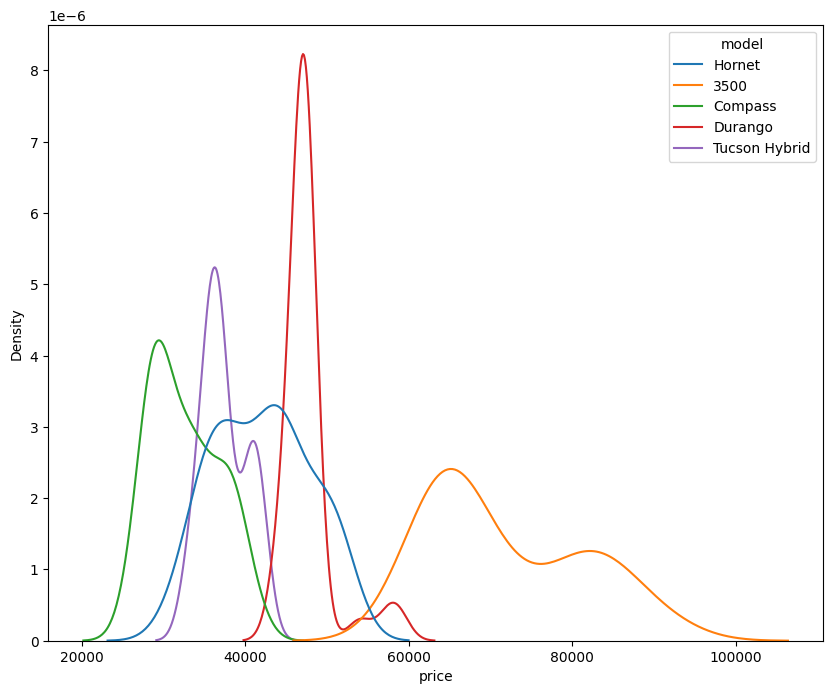

In [546]:
# to know if the model affect of car price or not
plt.figure(figsize=(10,8))
sns.kdeplot(data=data, x='price', hue='model', hue_order=data['model'].value_counts().index[:5]);

### 📊 Impact of the `model` Column on Price

According to the **previous plot**, we can observe that the **model of the car affects the price**. 💰🚘

For example:

* **Hornet** model is approximately in the range of **\$20,000  to  \$60,000**
* **Durango** model ranges approximately from **\$40,000 to \$60,000**

These patterns show that the **`model` column is relevant** for predicting price. 📈✅

In [547]:
data['model'].nunique()

150

In [548]:
print('unique values in X_train : ', X_train['model'].nunique())
print('unique values in X_test : ',X_test['model'].nunique())

unique values in X_train :  139
unique values in X_test :  72


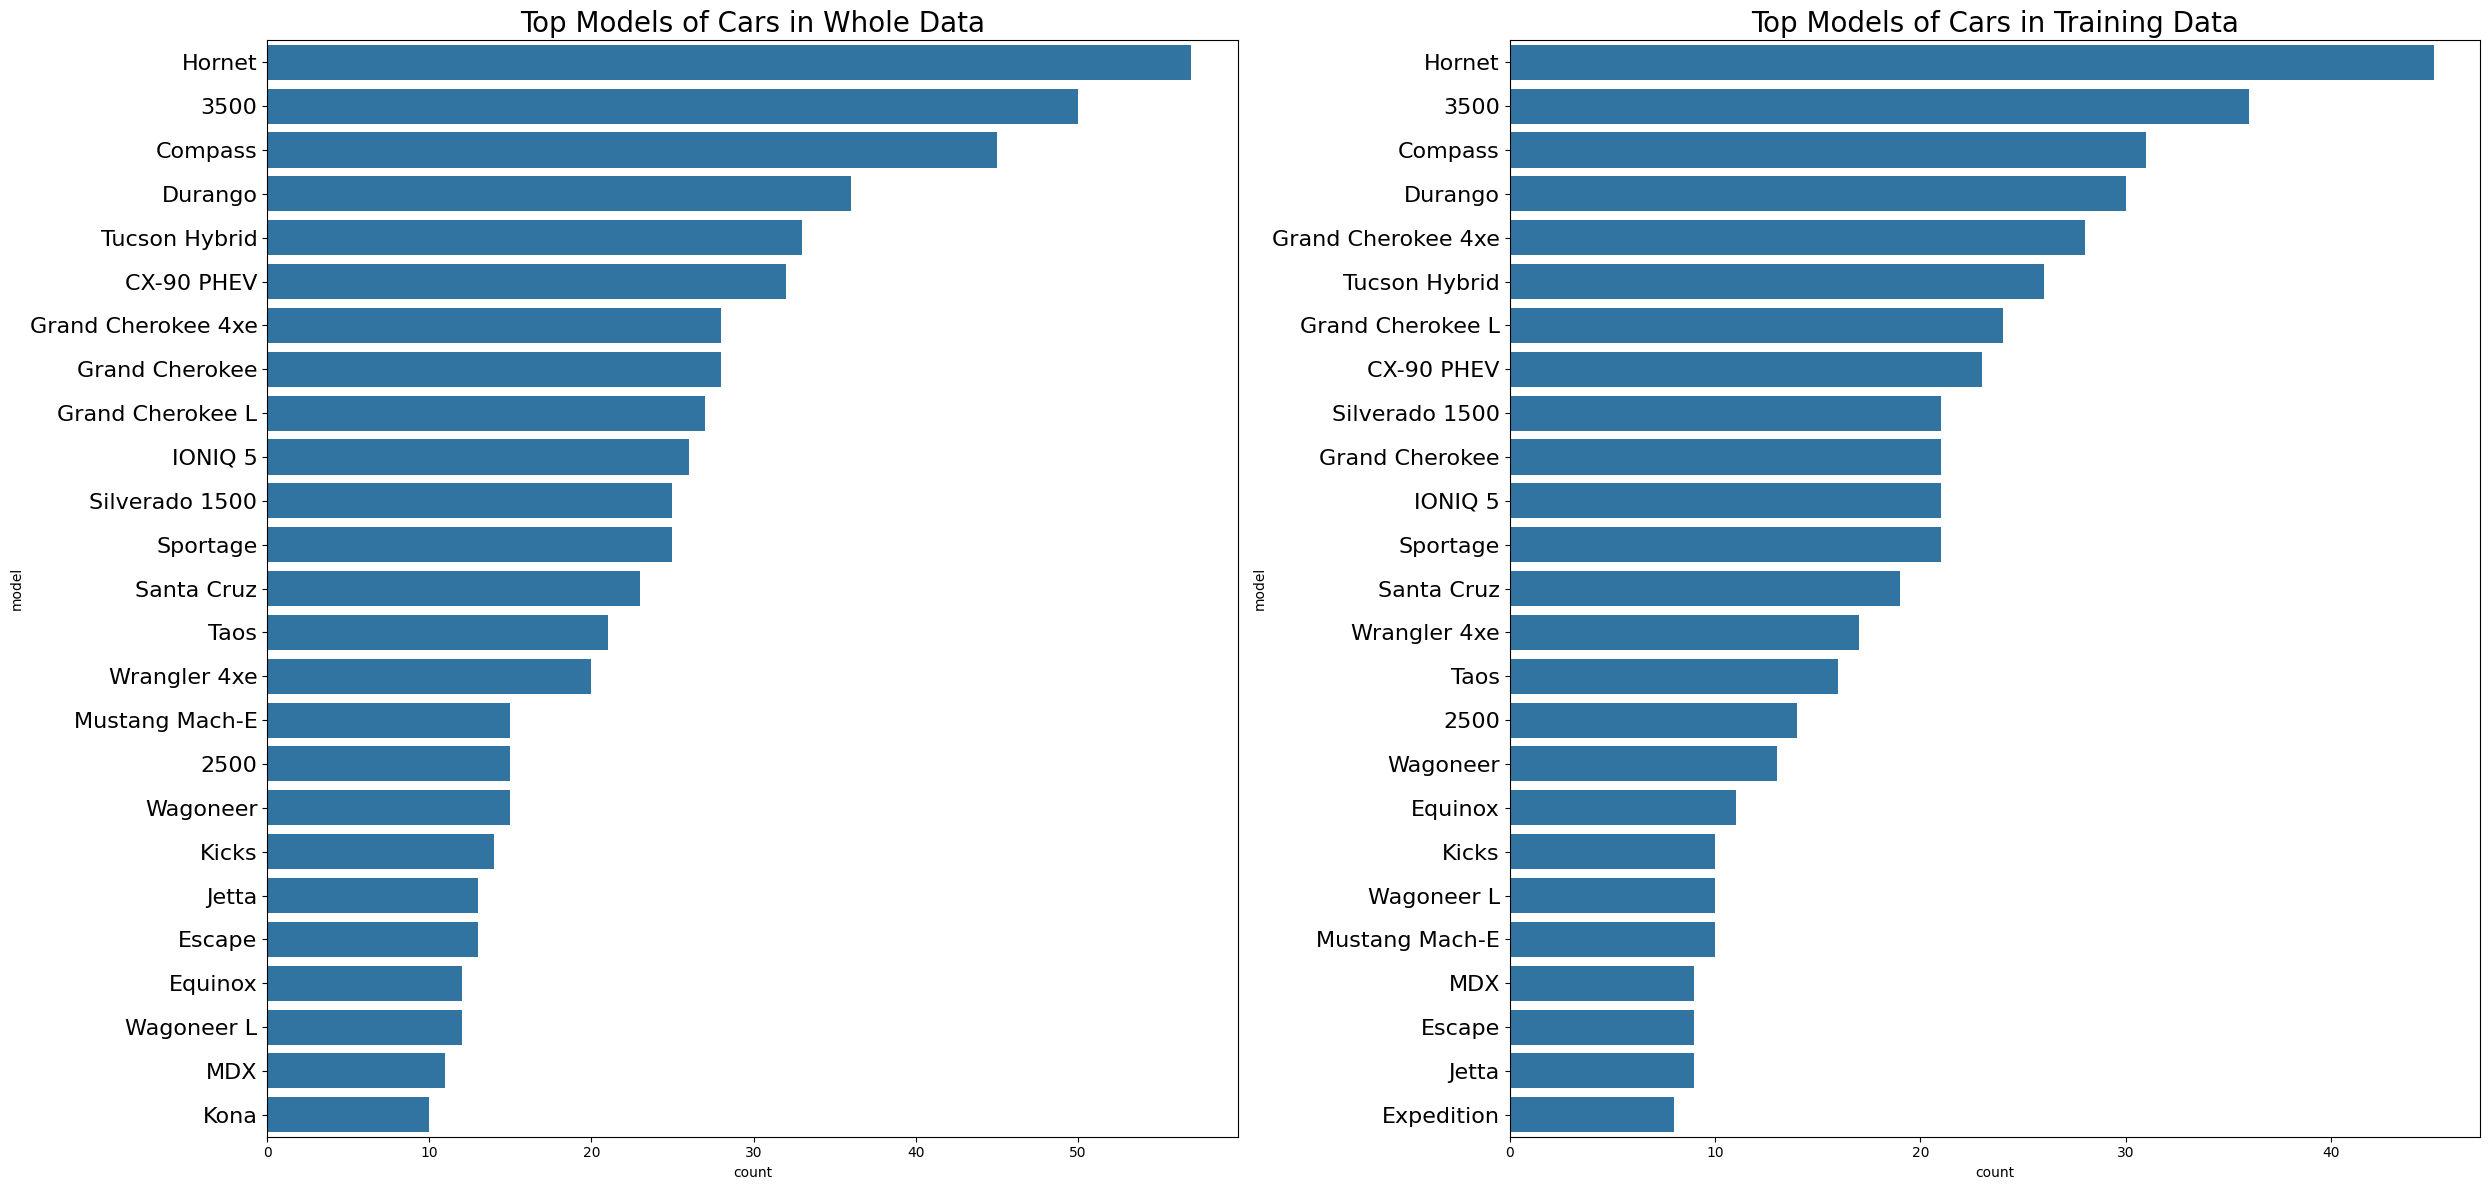

In [549]:
plt.figure(figsize=(25, 12))

# First subplot
plt.subplot(1, 2, 1)
sns.countplot(data=data, y='model', order=data['model'].value_counts().index[:25])
plt.yticks(fontsize=16)
plt.title('Top Models of Cars in Whole Data', fontsize=20)

# Second subplot
plt.subplot(1, 2, 2)
sns.countplot(data=X_train, y='model', order=X_train['model'].value_counts().index[:25])
plt.yticks(fontsize=16)
plt.title('Top Models of Cars in Training Data', fontsize=20)

plt.tight_layout();

### ⚠️ High Cardinality in the `model` Column

The problem is that the **number of unique values** in the `model` column is too high. **151 unique values**, and many of them appear **only once**. 🔢😕

To reduce **cardinality**, I will **replace infrequent values with `'other'`**.
This helps simplify the data and avoid overfitting. 🧹📉

In [550]:
top_k = 25
top_models = X_train['model'].value_counts().nlargest(top_k).index
top_models

Index(['Hornet', '3500', 'Compass', 'Durango', 'Grand Cherokee 4xe',
       'Tucson Hybrid', 'Grand Cherokee L', 'CX-90 PHEV', 'Silverado 1500',
       'Grand Cherokee', 'IONIQ 5', 'Sportage', 'Santa Cruz', 'Wrangler 4xe',
       'Taos', '2500', 'Wagoneer', 'Equinox', 'Kicks', 'Wagoneer L',
       'Mustang Mach-E', 'MDX', 'Escape', 'Jetta', 'Expedition'],
      dtype='object', name='model')

In [551]:
# Step 3: Apply transformation for top_models only
X_train['model_grouped'] = X_train['model'].where(X_train['model'].isin(top_models), 'other')
X_train.head(2)

,make,model,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped
321,26.0,Jetta,2024,"4 gasoline direct injection, DOHC, variable va...",4.0,3.0,7.0,8-Speed Automatic with Tiptronic,1.4T SE,6.0,4.0,0.0,0.0,1.0,0.0,Jetta
225,26.0,Taos,2024,16V GDI DOHC Turbo,4.0,3.0,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,5.0,4.0,1.0,0.0,0.0,0.0,Taos


In [552]:
X_train = X_train.drop(columns=['model'])
X_train.head(2)

,make,year,engine,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped
321,26.0,2024,"4 gasoline direct injection, DOHC, variable va...",4.0,3.0,7.0,8-Speed Automatic with Tiptronic,1.4T SE,6.0,4.0,0.0,0.0,1.0,0.0,Jetta
225,26.0,2024,16V GDI DOHC Turbo,4.0,3.0,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,5.0,4.0,1.0,0.0,0.0,0.0,Taos


In [553]:
X_train['model_grouped'].nunique()

26

25 Models
+
Other
=
26 Unique Values

In [554]:
ohe_model =OneHotEncoder(sparse_output=False,handle_unknown='ignore')
model_encoded = ohe_model.fit_transform(X_train[['model_grouped']])
model_encoded.shape

(756, 26)

In [555]:
model_df = pd.DataFrame(model_encoded, columns=ohe_model.get_feature_names_out(['model_grouped']), index=X_train.index)
model_df.head()

,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other
321,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
225,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
815,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
630,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
445,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [556]:
X_train = pd.concat([X_train, model_df], axis=1)
X_train = X_train.drop(columns=['model_grouped'])
X_train.shape

(756, 40)

#### Engine

In [557]:
X_train['engine'].nunique()

90

In [558]:
X_train['engine'].value_counts().nlargest(30)

engine
16V GDI DOHC Turbo                                           88
16V GDI DOHC Turbo Hybrid                                    83
c                                                            68
24V MPFI DOHC                                                39
16V MPFI OHV                                                 36
16V PDI DOHC                                                 32
24V GDI DOHC Twin Turbo                                      23
4 gasoline direct injection, DOHC, variable valve control    21
ar 3.6L V-6 DOHC, variable valve control, regular unleade    19
24V DDI OHV Turbo Diesel                                     19
16V GDI DOHC Hybrid                                          17
OHV                                                          17
16V GDI OHV                                                  16
gasoline direct injection, DOHC, variable valve control,     16
16V MPFI DOHC                                                15
24V GDI SOHC                     

### We can extract the following features
| Feature        | Pattern                              |
| -------------- | ------------------------------------ |
| V6 engine      | `'V-6'`, `'3.6L'`, `'v6'`            |
| V8 engine      | `'V-8'`, `'5.6L'`, `'v8'`            |
| I4 engine      | `'I-4'`, `'2.0L'`     |
| Turbocharged   | `'Turbo'`         |
| Hybrid         | `'Hybrid'`      |
| Diesel         | `'Diesel'`        |
| Electric       | `'Electric'`, `'EV'`, `'ZEV'`        |
| Cylinder count | `'16V'`, `'24V'`, `'12V'`            |
| Fuel system    | `'GDI'`, `'MPFI'`, `'PDI'`           |
| Valve control  | `'DOHC'`, `'SOHC'`, `'OHV'`, `'VVT'` |

In [559]:
def extract_engine_features(engine_str):
    engine_str = str(engine_str).lower()
    return {
        'is_v6': int('v-6' in engine_str or '3.6l' in engine_str),
        'is_v8': int('v-8' in engine_str or '5.6l' in engine_str),
        'is_i4': int('i-4' in engine_str or '2.0l' in engine_str),
        'is_turbo': int('turbo' in engine_str),
        'is_hybrid': int('hybrid' in engine_str),
        'is_diesel': int('diesel' in engine_str),
        'is_electric': int('electric' in engine_str or 'zev' in engine_str or 'ev' in engine_str),
        'valves_16v': int('16v' in engine_str),
        'valves_24v': int('24v' in engine_str),
        'valves_12v': int('12v' in engine_str),
        'is_dohc': int('dohc' in engine_str),
        'is_sohc': int('sohc' in engine_str),
        'is_ohv': int('ohv' in engine_str),
        'has_vvt': int('vvt' in engine_str)
    }

In [560]:
X_train['engine'].apply(extract_engine_features).apply(pd.Series)

,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt
321,0,0,0,0,0,0,0,0,0,0,1,0,0,0
225,0,0,0,1,0,0,0,1,0,0,1,0,0,0
815,0,0,0,0,0,0,0,0,1,0,0,1,0,0
630,0,0,0,0,0,0,0,0,0,0,0,0,0,0
445,0,0,0,0,0,0,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
947,0,0,0,1,1,0,0,1,0,0,1,0,0,0
320,0,0,0,0,0,0,0,0,0,0,1,0,0,0
956,0,0,0,1,1,0,0,1,0,0,1,0,0,0
586,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [561]:
engine_features_train = X_train['engine'].apply(extract_engine_features).apply(pd.Series)
engine_features_train

,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt
321,0,0,0,0,0,0,0,0,0,0,1,0,0,0
225,0,0,0,1,0,0,0,1,0,0,1,0,0,0
815,0,0,0,0,0,0,0,0,1,0,0,1,0,0
630,0,0,0,0,0,0,0,0,0,0,0,0,0,0
445,0,0,0,0,0,0,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
947,0,0,0,1,1,0,0,1,0,0,1,0,0,0
320,0,0,0,0,0,0,0,0,0,0,1,0,0,0
956,0,0,0,1,1,0,0,1,0,0,1,0,0,0
586,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [562]:
# Append to your dataset
X_train = pd.concat([X_train, engine_features_train], axis=1)
X_train = X_train.drop(columns = ['engine'])
X_train.head(3)

,make,year,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt
321,26.0,2024,4.0,3.0,7.0,8-Speed Automatic with Tiptronic,1.4T SE,6.0,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
225,26.0,2024,4.0,3.0,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,1,0,0,1,0,0,0
815,11.0,2024,6.0,3.0,0.0,9-Speed Automatic,TrailSport,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0


In [563]:
# To show all columns
pd.set_option('display.max_columns', None)

In [564]:
X_train.head(3)

,make,year,cylinders,fuel,mileage,transmission,trim,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt
321,26.0,2024,4.0,3.0,7.0,8-Speed Automatic with Tiptronic,1.4T SE,6.0,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
225,26.0,2024,4.0,3.0,8.0,7-Speed DSGA? Automatic w/ 4MO,1.5T S,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,1,0,0,1,0,0,0
815,11.0,2024,6.0,3.0,0.0,9-Speed Automatic,TrailSport,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0


#### Transmission

In [565]:
X_train["transmission"].value_counts()

transmission
8-Speed Automatic                              249
Automatic                                      179
6-Speed Automatic                               78
1-Speed Automatic                               49
9-Speed Automatic                               47
10-Speed Automatic                              46
Automatic CVT                                   34
8-Speed Automatic with Auto-Shift               12
7-Speed DSGA? Automatic w/ 4MO                   8
8-Speed Automatic with Tiptronic                 8
CVT                                              5
8-Speed A/T                                      4
7-Speed Automatic S tronic                       4
7-Speed Automatic with Auto-Shift                3
6-Speed Automatic Electronic with Overdrive      3
7-Speed DSG Automatic with Tiptronic             3
8-speed automatic                                3
6-Spd Aisin F21-250 PHEV Auto Trans              3
Variable                                         3
9-Speed 948TE Auto

In [566]:
X_train["transmission"].unique()

array(['8-Speed Automatic with Tiptronic',
       '7-Speed DSGA? Automatic w/ 4MO', '9-Speed Automatic', 'Automatic',
       '8-Speed Automatic', '7-Speed Automatic with Auto-Shift',
       '1-Speed Automatic', '6-Speed Automatic', 'Automatic CVT',
       '10-Speed Automatic', '8-Speed A/T',
       '8-Speed Automatic with Auto-Shift', '7-Speed Automatic S tronic',
       'CVT', '6-Speed DCT Automatic', 'automatic w/paddle shifters',
       'A/T', '7-Speed DSG Automatic with Tiptronic',
       '6-Speed Automatic Electronic with Overdrive', '6-SPEED AUTOMATIC',
       '9-Speed 948TE Automatic', 'Variable', '8-speed automatic',
       '6-Spd Aisin F21-250 PHEV Auto Trans', '9-Speed A/T',
       '8-Speed Automatic Sport', '10-Speed Automatic with Overdrive',
       '9-speed automatic', '8 Speed Dual Clutch', 'CVT with Xtronic',
       '6-Speed A/T', 'Aisin 6-Speed Automatic'], dtype=object)

In [567]:
X_train["transmission"].isnull().sum()

np.int64(0)

In [568]:
transmission_lower=X_train["transmission"].str.lower()
print(transmission_lower.nunique())

29


In [569]:
transmission_lower.value_counts().loc[
    lambda counts: counts == 1
]

transmission
6-speed dct automatic                1
a/t                                  1
automatic w/paddle shifters          1
9-speed a/t                          1
8-speed automatic sport              1
10-speed automatic with overdrive    1
8 speed dual clutch                  1
cvt with xtronic                     1
6-speed a/t                          1
aisin 6-speed automatic              1
Name: count, dtype: int64

In [570]:
transmission_lower.value_counts().loc[
    lambda counts: counts <= 5
]

transmission
cvt                                            5
7-speed automatic s tronic                     4
8-speed a/t                                    4
7-speed automatic with auto-shift              3
9-speed 948te automatic                        3
6-speed automatic electronic with overdrive    3
7-speed dsg automatic with tiptronic           3
variable                                       3
6-spd aisin f21-250 phev auto trans            3
6-speed dct automatic                          1
a/t                                            1
automatic w/paddle shifters                    1
9-speed a/t                                    1
8-speed automatic sport                        1
10-speed automatic with overdrive              1
8 speed dual clutch                            1
cvt with xtronic                               1
6-speed a/t                                    1
aisin 6-speed automatic                        1
Name: count, dtype: int64

In [571]:
import re as re
def extract_transmission_features(t):
 t = str(t).lower()
 m = re.search(r'(\d+)\s*-?\s*(?:speed|spd)', t)
 return {
        'gears': int(m.group(1)) if m else np.nan,
        'is_cvt': int('cvt' in t or 'variable' in t),
        'is_dual_clutch': int(any(k in t for k in ['dsg', 'dct', 'dual clutch', 's tronic'])),
        'has_manual_mode': int(any(k in t for k in ['tiptronic', 'paddle', 'auto-shift', 'autoshift']))
    }

In [572]:
rare_values=transmission_lower.value_counts().loc[
    lambda counts: counts <= 5
].index
pd.DataFrame({'original':rare_values}).join(
    pd.Series(rare_values).apply(extract_transmission_features).apply(pd.Series)
)

,original,gears,is_cvt,is_dual_clutch,has_manual_mode
0,cvt,NaN,1.0,0.0,0.0
1,7-speed automatic s tronic,7.0,0.0,1.0,0.0
2,8-speed a/t,8.0,0.0,0.0,0.0
3,7-speed automatic with auto-shift,7.0,0.0,0.0,1.0
4,9-speed 948te automatic,9.0,0.0,0.0,0.0
5,6-speed automatic electronic with overdrive,6.0,0.0,0.0,0.0
6,7-speed dsg automatic with tiptronic,7.0,0.0,1.0,1.0
7,variable,NaN,1.0,0.0,0.0
8,6-spd aisin f21-250 phev auto trans,6.0,0.0,0.0,0.0
9,6-speed dct automatic,6.0,0.0,1.0,0.0


In [573]:
transmission_features_train = X_train['transmission'].apply(extract_transmission_features).apply(pd.Series)
transmission_features_train.head()

,gears,is_cvt,is_dual_clutch,has_manual_mode
321,8.0,0.0,0.0,1.0
225,7.0,0.0,1.0,0.0
815,9.0,0.0,0.0,0.0
630,NaN,0.0,0.0,0.0
445,NaN,0.0,0.0,0.0


In [574]:
transmission_features_train['gears'].isnull().sum()

np.int64(224)

In [575]:
gears_median=transmission_features_train['gears'].median()
gears_median

8.0

In [576]:
transmission_features_train['gears'] = transmission_features_train['gears'].fillna(gears_median)
transmission_features_train.head()

,gears,is_cvt,is_dual_clutch,has_manual_mode
321,8.0,0.0,0.0,1.0
225,7.0,0.0,1.0,0.0
815,9.0,0.0,0.0,0.0
630,8.0,0.0,0.0,0.0
445,8.0,0.0,0.0,0.0


In [577]:
transmission_features_train['gears'].isnull().sum()

np.int64(0)

In [578]:
X_train = pd.concat([X_train, transmission_features_train], axis=1)
X_train = X_train.drop(columns=['transmission'])
X_train.head(3)

,make,year,cylinders,fuel,mileage,trim,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt,gears,is_cvt,is_dual_clutch,has_manual_mode
321,26.0,2024,4.0,3.0,7.0,1.4T SE,6.0,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,8.0,0.0,0.0,1.0
225,26.0,2024,4.0,3.0,8.0,1.5T S,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,7.0,0.0,1.0,0.0
815,11.0,2024,6.0,3.0,0.0,TrailSport,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,9.0,0.0,0.0,0.0


#### Trim

In [579]:
X_train['trim'].value_counts()

trim
Limited                                      50
Base                                         46
SEL                                          30
Pursuit                                      25
Tradesman                                    21
                                             ..
XRT                                           1
ZR2                                           1
i                                             1
Premium 55 TFSI e S line quattro S tronic     1
Denali Ultimate                               1
Name: count, Length: 182, dtype: int64

In [580]:
X_train['trim'].unique()

array(['1.4T SE', '1.5T S', 'TrailSport', 'SEL', 'Sport', 'ST-Line Elite',
       'Summit', 'Laramie Crew Cab 4x4 8&#39; Box', 'Standard Roof',
       'Base', 'Sport S', 'Touring-L', 'Premium', 'Limited',
       '2.0T Peak Edition SE w/Technology', 'SEL Convenience', 'S',
       'EX-L', 'Trailhawk', 'Latitude', 'SV', 'ST-Line', 'GT', '1.4T S',
       'LT', '1.5T SE', 'quattro', 'SX X-Pro', 'R/T', 'SLE', 'xDrive40',
       'High Roof', 'Laredo', 'SE Standard Range', '4MATIC', '2.5 SV',
       'Series II Carbide 4x4', 'Blue', '2.5T Limited', '55 Premium Plus',
       'XLT', '55 Prestige', 'Custom Trail Boss', 'Preferred', 'Wind',
       'Free Wheeling', 'T8 Plus Bright Theme 7 Passenger',
       'S line Premium Plus', 'Big Horn', 'S line Premium', 'Sport w/1SF',
       '144 WB Standard Roof Passenger', 'Laramie', 'Low Roof',
       'X-Pro Prestige', 'Tradesman', 'Calligraphy', 'Pursuit',
       'Anniversary Edition', 'Rubicon', 'R/T Plus', 'LT Trail Boss',
       'Sahara', 'F SPORT PERFO

In [581]:
X_train['trim'].isnull().sum()

np.int64(0)

In [582]:
#احنا هنا بنقيس المشكله في الاول 
trim_counts=X_train["trim"].value_counts()
print('unique trims      :', X_train['trim'].nunique())
print('appear once',(trim_counts==1).sum())
print('appear <= 5 times',(trim_counts<=5).sum())
print('contains &#39;    :', X_train['trim'].str.contains('&#39;').sum())

unique trims      : 182
appear once 83
appear <= 5 times 146
contains &#39;    : 10


In [583]:
for k in [10, 20, 30, 50]:
    share = trim_counts.nlargest(k).sum() / len(X_train) * 100
    print(f'top {k} trims cover {share:.1f}% of the data')

top 10 trims cover 33.1% of the data
top 20 trims cover 48.0% of the data
top 30 trims cover 58.9% of the data
top 50 trims cover 72.4% of the data


In [584]:
# X_train = x_train.copy()
# del x_train
# X_train.columns

In [585]:
top_k = 30
top_trims = X_train['trim'].value_counts().nlargest(top_k).index

X_train['trim_grouped'] = X_train['trim'].where(X_train['trim'].isin(top_trims), 'other')
X_train = X_train.drop(columns=['trim'])
X_train.head(3)

,make,year,cylinders,fuel,mileage,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt,gears,is_cvt,is_dual_clutch,has_manual_mode,trim_grouped
321,26.0,2024,4.0,3.0,7.0,6.0,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,8.0,0.0,0.0,1.0,other
225,26.0,2024,4.0,3.0,8.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,7.0,0.0,1.0,0.0,other
815,11.0,2024,6.0,3.0,0.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,9.0,0.0,0.0,0.0,other


In [586]:
X_train['trim_grouped'].nunique()

31

In [587]:
X_train['trim_grouped'].value_counts()

trim_grouped
other              311
Limited             50
Base                46
SEL                 30
Pursuit             25
Tradesman           21
Premium             20
Latitude            19
Laredo              14
R/T Plus            13
GT                  12
R/T                 12
Trailhawk           12
1.5T SE             12
SEL Convenience     12
Series II           12
LT                  11
S                   11
SV                  11
Sport               10
XLT                 10
Rubicon             10
High Roof            9
GT AWD               9
Blue                 8
Laramie              8
Altitude             8
Base 4MATIC          8
EX                   8
X-Line               7
2.5L SEL             7
Name: count, dtype: int64

In [588]:
othe_trims= OneHotEncoder(sparse_output=False,handle_unknown='ignore')
trim_encoded = othe_trims.fit_transform(X_train[['trim_grouped']])

trim_features = pd.DataFrame(trim_encoded, columns=othe_trims.get_feature_names_out(['trim_grouped']), index=X_train.index)
trim_features.head()

,trim_grouped_1.5T SE,trim_grouped_2.5L SEL,trim_grouped_Altitude,trim_grouped_Base,trim_grouped_Base 4MATIC,trim_grouped_Blue,trim_grouped_EX,trim_grouped_GT,trim_grouped_GT AWD,trim_grouped_High Roof,trim_grouped_LT,trim_grouped_Laramie,trim_grouped_Laredo,trim_grouped_Latitude,trim_grouped_Limited,trim_grouped_Premium,trim_grouped_Pursuit,trim_grouped_R/T,trim_grouped_R/T Plus,trim_grouped_Rubicon,trim_grouped_S,trim_grouped_SEL,trim_grouped_SEL Convenience,trim_grouped_SV,trim_grouped_Series II,trim_grouped_Sport,trim_grouped_Tradesman,trim_grouped_Trailhawk,trim_grouped_X-Line,trim_grouped_XLT,trim_grouped_other
321,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
225,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
815,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
630,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
445,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [589]:
X_train = pd.concat([X_train, trim_features], axis=1)
X_train

,make,year,cylinders,fuel,mileage,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt,gears,is_cvt,is_dual_clutch,has_manual_mode,trim_grouped,trim_grouped_1.5T SE,trim_grouped_2.5L SEL,trim_grouped_Altitude,trim_grouped_Base,trim_grouped_Base 4MATIC,trim_grouped_Blue,trim_grouped_EX,trim_grouped_GT,trim_grouped_GT AWD,trim_grouped_High Roof,trim_grouped_LT,trim_grouped_Laramie,trim_grouped_Laredo,trim_grouped_Latitude,trim_grouped_Limited,trim_grouped_Premium,trim_grouped_Pursuit,trim_grouped_R/T,trim_grouped_R/T Plus,trim_grouped_Rubicon,trim_grouped_S,trim_grouped_SEL,trim_grouped_SEL Convenience,trim_grouped_SV,trim_grouped_Series II,trim_grouped_Sport,trim_grouped_Tradesman,trim_grouped_Trailhawk,trim_grouped_X-Line,trim_grouped_XLT,trim_grouped_other
321,26.0,2024,4.0,3.0,7.0,6.0,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,8.0,0.0,0.0,1.0,other,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
225,26.0,2024,4.0,3.0,8.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,7.0,0.0,1.0,0.0,other,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
815,11.0,2024,6.0,3.0,0.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,9.0,0.0,0.0,0.0,other,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
630,12.0,2024,4.0,2.0,0.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.0,0.0,0.0,0.0,SEL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
445,15.0,2024,6.0,3.0,12.0,4.0,4.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,8.0,0.0,0.0,0.0,Sport,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
947,15.0,2024,4.0,4.0,11.0,5.0,4.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,8.0,0.0,0.0,0.0,Base,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
320,1.0,2024,4.0,3.0,12.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0

In [590]:
X_train = X_train.drop(columns=['trim_grouped'])
X_train.head(3)

,make,year,cylinders,fuel,mileage,body,doors,drivetrain_All-wheel Drive,drivetrain_Four-wheel Drive,drivetrain_Front-wheel Drive,drivetrain_Rear-wheel Drive,model_grouped_2500,model_grouped_3500,model_grouped_CX-90 PHEV,model_grouped_Compass,model_grouped_Durango,model_grouped_Equinox,model_grouped_Escape,model_grouped_Expedition,model_grouped_Grand Cherokee,model_grouped_Grand Cherokee 4xe,model_grouped_Grand Cherokee L,model_grouped_Hornet,model_grouped_IONIQ 5,model_grouped_Jetta,model_grouped_Kicks,model_grouped_MDX,model_grouped_Mustang Mach-E,model_grouped_Santa Cruz,model_grouped_Silverado 1500,model_grouped_Sportage,model_grouped_Taos,model_grouped_Tucson Hybrid,model_grouped_Wagoneer,model_grouped_Wagoneer L,model_grouped_Wrangler 4xe,model_grouped_other,is_v6,is_v8,is_i4,is_turbo,is_hybrid,is_diesel,is_electric,valves_16v,valves_24v,valves_12v,is_dohc,is_sohc,is_ohv,has_vvt,gears,is_cvt,is_dual_clutch,has_manual_mode,trim_grouped_1.5T SE,trim_grouped_2.5L SEL,trim_grouped_Altitude,trim_grouped_Base,trim_grouped_Base 4MATIC,trim_grouped_Blue,trim_grouped_EX,trim_grouped_GT,trim_grouped_GT AWD,trim_grouped_High Roof,trim_grouped_LT,trim_grouped_Laramie,trim_grouped_Laredo,trim_grouped_Latitude,trim_grouped_Limited,trim_grouped_Premium,trim_grouped_Pursuit,trim_grouped_R/T,trim_grouped_R/T Plus,trim_grouped_Rubicon,trim_grouped_S,trim_grouped_SEL,trim_grouped_SEL Convenience,trim_grouped_SV,trim_grouped_Series II,trim_grouped_Sport,trim_grouped_Tradesman,trim_grouped_Trailhawk,trim_grouped_X-Line,trim_grouped_XLT,trim_grouped_other
321,26.0,2024,4.0,3.0,7.0,6.0,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
225,26.0,2024,4.0,3.0,8.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,7.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
815,11.0,2024,6.0,3.0,0.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [591]:
X_train.shape

(756, 86)

### Final Data Check

Check that all features are numeric and there are no missing values before training the model.

In [592]:
print("non-numeric columns:", X_train.select_dtypes(exclude='number').columns.tolist())
print("total NaN          :", X_train.isna().sum().sum())

non-numeric columns: []
total NaN          : 0


### Feature Scaling

Apply `RobustScaler` to the numerical features in `X_train` to scale their values and reduce the influence of outliers.

In [593]:
from sklearn.preprocessing import RobustScaler
numeric_cols = ['year', 'cylinders', 'mileage', 'doors', 'gears']
scaler= RobustScaler()
X_scaled = X_train.copy()
X_scaled[numeric_cols]=scaler.fit_transform(X_scaled[numeric_cols])
X_scaled[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
year,756.0,-0.076720,0.290125,-1.0,0.0,0.0,0.0,1.000
cylinders,756.0,0.485450,0.687003,-2.0,0.0,0.0,1.0,2.000
mileage,756.0,5.261905,44.595636,-1.0,-0.5,0.0,0.5,589.375
doors,756.0,-0.055556,0.276369,-2.0,0.0,0.0,0.0,1.000
gears,756.0,-0.517196,1.928791,-7.0,0.0,0.0,0.0,2.000


### Feature Selection

Select the most useful features for the model and remove features that provide little or no useful information.

In [594]:
X_scaled.var().sort_values(ascending=False)

mileage                  1988.770760
make                       43.334152
gears                       3.720234
body                        1.201759
fuel                        0.952066
                            ...     
trim_grouped_Blue           0.010484
trim_grouped_EX             0.010484
trim_grouped_Laramie        0.010484
trim_grouped_2.5L SEL       0.009186
trim_grouped_X-Line         0.009186
Length: 86, dtype: float64

In [595]:
for th in [0.1, 0.05, 0.01, 0.001]:
    kept = (X_scaled.var() > th).sum()
    print(f'threshold {th}: keeps {kept} of {X_scaled.shape[1]} columns')

threshold 0.1: keeps 17 of 86 columns
threshold 0.05: keeps 25 of 86 columns
threshold 0.01: keeps 84 of 86 columns
threshold 0.001: keeps 86 of 86 columns


### Why We Skip Variance Threshold

We skip `VarianceThreshold` for now because:

- All features have some variance.
- It may remove useful but rare categories.
- It does not consider the target (`price`) when selecting features.

We will explore other feature selection methods later.

### Baseline Model Evaluation

Evaluate simple models using 5-fold cross-validation to establish a baseline for performance comparison.

We use **R²** and **MAE** to compare the models and guide the next steps.

cross validation ![image.png](attachment:8b250aae-8562-4e35-8a54-972a30466440.png)

In [596]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

dummy = DummyRegressor(strategy='mean')
r2 = cross_val_score(dummy, X_scaled, y_train, cv=5, scoring='r2')
mae = -cross_val_score(dummy, X_scaled, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f'Dummy: R2 = {r2.mean():.3f} | MAE = {mae.mean():,.0f}')

Dummy: R2 = -0.004 | MAE = 13,856


In [597]:
from sklearn.linear_model import LinearRegression
linear_regression= LinearRegression()
r2 = cross_val_score(linear_regression, X_scaled, y_train, cv=5, scoring='r2')
mae = -cross_val_score(linear_regression, X_scaled, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f'LinearRegression: R2 = {r2.mean():.3f} | MAE = {mae.mean():,.0f}')

LinearRegression: R2 = 0.590 | MAE = 7,403


In [598]:
from sklearn.ensemble import RandomForestRegressor
RandomForest= RandomForestRegressor(random_state=32)
r2 = cross_val_score(RandomForest, X_scaled, y_train, cv=5, scoring='r2')
mae = -cross_val_score(RandomForest, X_scaled, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f'RandomForest: R2 = {r2.mean():.3f} | MAE = {mae.mean():,.0f}')

RandomForest: R2 = 0.735 | MAE = 5,186


In [599]:
from sklearn.tree import DecisionTreeRegressor
DecisionTree=DecisionTreeRegressor(random_state=32)
r2 = cross_val_score(DecisionTree, X_scaled, y_train, cv=5, scoring='r2')
mae = -cross_val_score(DecisionTree, X_scaled, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f'DecisionTree: R2 = {r2.mean():.3f} | MAE = {mae.mean():,.0f}')

DecisionTree: R2 = 0.640 | MAE = 5,637



## Pipeline Preparation

We are currently preparing the machine learning pipeline by organizing the preprocessing steps and defining how the features will be transformed before training the model.

The goal is to ensure a consistent workflow for training and making predictions while preventing data leakage.

In [600]:
#الداتا الخام لنفس عربيات الـ train
X_train_raw = X.loc[y_train.index]

print('raw train shape :', X_train_raw.shape)
print('raw test shape  :', X_test.shape)
print(list(X_train_raw.columns))

raw train shape : (756, 12)
raw test shape  : (190, 12)
['make', 'model', 'year', 'engine', 'cylinders', 'fuel', 'mileage', 'transmission', 'trim', 'body', 'doors', 'drivetrain']


In [601]:
from sklearn.base import BaseEstimator, TransformerMixin

class ExtractEngineFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, col='engine'):
        self.col = col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        def extract_features(engine_str):
            engine_str = str(engine_str).lower()
            return {
                'is_v6': int('v-6' in engine_str or '3.6l' in engine_str),
                'is_v8': int('v-8' in engine_str or '5.6l' in engine_str),
                'is_i4': int('i-4' in engine_str or '2.0l' in engine_str),
                'is_turbo': int('turbo' in engine_str),
                'is_hybrid': int('hybrid' in engine_str),
                'is_diesel': int('diesel' in engine_str),
                'is_electric': int('electric' in engine_str or 'zev' in engine_str or 'ev' in engine_str),
                'valves_16v': int('16v' in engine_str),
                'valves_24v': int('24v' in engine_str),
                'valves_12v': int('12v' in engine_str),
                'is_dohc': int('dohc' in engine_str),
                'is_sohc': int('sohc' in engine_str),
                'is_ohv': int('ohv' in engine_str),
                'has_vvt': int('vvt' in engine_str)
            }

        features = X[self.col].apply(extract_features).apply(pd.Series)
        X = pd.concat([X, features], axis=1)
        X = X.drop(columns=[self.col])
        return X

In [602]:
engine_step = ExtractEngineFeatures()
engine_out = engine_step.fit_transform(X_train_raw)

print('raw shape    :', X_train_raw.shape)
print('output shape :', engine_out.shape)
print('engine still there?', 'engine' in engine_out.columns)

raw shape    : (756, 12)
output shape : (756, 25)
engine still there? False


In [603]:
class ExtractTransmissionFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, col='transmission'):
        self.col = col

    def fit(self, X, y=None):
        features = X[self.col].apply(extract_transmission_features).apply(pd.Series)
        self.gears_median_ = features['gears'].median()
        return self

    def transform(self, X):
        X = X.copy()
        features = X[self.col].apply(extract_transmission_features).apply(pd.Series)
        features['gears'] = features['gears'].fillna(self.gears_median_)
        X = pd.concat([X, features], axis=1)
        X = X.drop(columns=[self.col])
        return X

In [604]:
trans_step = ExtractTransmissionFeatures()
trans_out = trans_step.fit_transform(engine_out)

print('input shape  :', engine_out.shape)
print('output shape :', trans_out.shape)
print('transmission still there?', 'transmission' in trans_out.columns)
print('NaN in gears :', trans_out['gears'].isnull().sum())
print('learned median:', trans_step.gears_median_, '| old median:', gears_median)

input shape  : (756, 25)
output shape : (756, 28)
transmission still there? False
NaN in gears : 0
learned median: 8.0 | old median: 8.0


In [605]:
class GroupRareCategories(BaseEstimator, TransformerMixin):
    def __init__(self, col, top_k=25):
        self.col = col
        self.top_k = top_k

    def fit(self, X, y=None):
        self.top_values_ = X[self.col].value_counts().nlargest(self.top_k).index
        return self

    def transform(self, X):
        X = X.copy()
        X[f'{self.col}_grouped'] = X[self.col].where(X[self.col].isin(self.top_values_), 'other')
        X = X.drop(columns=[self.col])
        return X

In [606]:
model_step = GroupRareCategories(col='model', top_k=25)
trim_step = GroupRareCategories(col='trim', top_k=30)

grouped_out = model_step.fit_transform(trans_out)
grouped_out = trim_step.fit_transform(grouped_out)

print('input shape  :', trans_out.shape)
print('output shape :', grouped_out.shape)
print('model_grouped unique:', grouped_out['model_grouped'].nunique())
print('trim_grouped unique :', grouped_out['trim_grouped'].nunique())
print('other trims :', (grouped_out['trim_grouped'] == 'other').sum())
print('same model list as manual?', set(model_step.top_values_) == set(top_models))
print('same trim list as manual? ', set(trim_step.top_values_) == set(top_trims))

input shape  : (756, 28)
output shape : (756, 28)
model_grouped unique: 26
trim_grouped unique : 31
other trims : 311
same model list as manual? True
same trim list as manual?  True


In [607]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler

ohe_cols = ['drivetrain', 'model_grouped', 'trim_grouped']
ordinal_cols = ['body', 'fuel', 'make']
numeric_cols = ['year', 'cylinders', 'mileage', 'doors', 'gears']

preprocessor = ColumnTransformer(
    transformers=[
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ohe_cols),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
        ('scale', RobustScaler(), numeric_cols),
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)
preprocessor.set_output(transform='pandas')

ColumnTransformer(remainder='passthrough',
                  transformers=[('ohe',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['drivetrain', 'model_grouped',
                                  'trim_grouped']),
                                ('ordinal',
                                 OrdinalEncoder(handle_unknown='use_encoded_value',
                                                unknown_value=-1),
                                 ['body', 'fuel', 'make']),
                                ('scale', RobustScaler(),
                                 ['year', 'cylinders', 'mileage', 'doors',
                                  'gears'])],
                  verbose_feature_names_out=False)

In [608]:
prep_out = preprocessor.fit_transform(grouped_out)

print('input shape :', grouped_out.shape)
print('output shape:', prep_out.shape)
print('non-numeric :', prep_out.select_dtypes(exclude='number').columns.tolist())
print('NaN         :', prep_out.isna().sum().sum())
print('same columns as X_scaled?', set(prep_out.columns) == set(X_scaled.columns))
print('same values as X_scaled? ', np.allclose(prep_out[X_scaled.columns].values, X_scaled.values))

input shape : (756, 28)
output shape: (756, 86)
non-numeric : []
NaN         : 0
same columns as X_scaled? True
same values as X_scaled?  True


In [609]:
from sklearn.pipeline import Pipeline

prep_pipe = Pipeline(steps=[
    ('engine', ExtractEngineFeatures()),
    ('transmission', ExtractTransmissionFeatures()),
    ('model_group', GroupRareCategories(col='model', top_k=25)),
    ('trim_group', GroupRareCategories(col='trim', top_k=30)),
    ('preprocessor', preprocessor),
])

X_train_ready = prep_pipe.fit_transform(X_train_raw)
X_test_ready = prep_pipe.transform(X_test)

In [610]:
print('train ready :', X_train_ready.shape)
print('test ready  :', X_test_ready.shape)
print('same columns & order?', list(X_train_ready.columns) == list(X_test_ready.columns))
print('NaN in test :', X_test_ready.isna().sum().sum())
print('same as X_scaled?', np.allclose(X_train_ready[X_scaled.columns].values, X_scaled.values))
print('gears median:', prep_pipe.named_steps['transmission'].gears_median_)

train ready : (756, 86)
test ready  : (190, 86)
same columns & order? True
NaN in test : 0
same as X_scaled? True
gears median: 8.0


## Step 6: Build the Full Pipeline and Evaluate the Model

### Where We Are
We have completed the preprocessing pipeline, including:
- Extracting engine and transmission features.
- Grouping rare `model` and `trim` categories.
- Applying encoding and scaling using `ColumnTransformer`.

The preprocessing pipeline has been tested and compared with our previous manual preprocessing.

### What We Will Do Now

1. **Build the Full Pipeline:** Combine all preprocessing steps with a `RandomForestRegressor`.
2. **Apply 5-Fold Cross-Validation:** Split the training data into five folds. In each fold, fit the preprocessing steps and model using only the training folds, then evaluate on the remaining fold.
3. **Evaluate Performance:**
   - **R²:** Measures how well the model explains price variations. Higher is generally better.
   - **MAE:** Measures the average absolute prediction error. Lower is better.
4. **Compare Results:** Use the average scores across the five folds to evaluate model performance.

### Important Notes
- Use `X_train_raw` and `y_train` as inputs to the full pipeline.
- Preprocessing parameters must be learned from each fold's training data only to avoid data leakage.
- Keep `X_test` separate for the final evaluation after model selection.

**Goal:** Build a reliable end-to-end preprocessing and modeling pipeline and establish a baseline for car price prediction.

In [611]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

full_pipe = Pipeline(steps=[
    ('engine', ExtractEngineFeatures()),
    ('transmission', ExtractTransmissionFeatures()),
    ('model_group', GroupRareCategories(col='model', top_k=25)),
    ('trim_group', GroupRareCategories(col='trim', top_k=30)),
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=32)),
])

r2 = cross_val_score(full_pipe, X_train_raw, y_train, cv=5, scoring='r2')
mae = -cross_val_score(full_pipe, X_train_raw, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f'RandomForest (full Pipeline): R2 = {r2.mean():.3f} | MAE = {mae.mean():,.0f}')

RandomForest (full Pipeline): R2 = 0.736 | MAE = 5,136


### Experiment 1: Model Comparison

In this step, we test two boosting models, `GradientBoostingRegressor` and `HistGradientBoostingRegressor`, and compare their performance against our baseline `RandomForestRegressor` (R² = 0.736).

All models use the same preprocessing pipeline and 5-fold cross-validation. We compare their R² and MAE scores to identify the best-performing model for the next optimization steps.

In [612]:
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor

def make_pipe(model):
    return Pipeline(steps=[
        ('engine', ExtractEngineFeatures()),
        ('transmission', ExtractTransmissionFeatures()),
        ('model_group', GroupRareCategories(col='model', top_k=25)),
        ('trim_group', GroupRareCategories(col='trim', top_k=30)),
        ('preprocessor', preprocessor),
        ('regressor', model),
    ])

candidates = {
    'GradientBoosting': GradientBoostingRegressor(random_state=32),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=32),
}

for name, m in candidates.items():
    pipe = make_pipe(m)
    r2 = cross_val_score(pipe, X_train_raw, y_train, cv=5, scoring='r2')
    mae = -cross_val_score(pipe, X_train_raw, y_train, cv=5, scoring='neg_mean_absolute_error')
    print(f'{name}: R2 = {r2.mean():.3f} | MAE = {mae.mean():,.0f}')

GradientBoosting: R2 = 0.678 | MAE = 6,149
HistGradientBoosting: R2 = 0.740 | MAE = 5,968


### Experiment 2: Random Forest Hyperparameter Tuning

We decided to keep `RandomForestRegressor` as our main model because the boosting models did not provide a significant overall improvement.

In this step, we will tune the Random Forest hyperparameters using `RandomizedSearchCV` to find a better configuration before moving on to further data and feature engineering improvements.

In [613]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'regressor__n_estimators': [200, 400, 600],
    'regressor__max_features': [0.2, 0.3, 0.5, 0.7, 1.0],
    'regressor__min_samples_leaf': [1, 2, 3, 5],
    'regressor__max_depth': [None, 10, 20, 30],
}

search = RandomizedSearchCV(
    full_pipe, param_dist, n_iter=50, cv=5,
    scoring='neg_mean_absolute_error', random_state=32, n_jobs=-1
)
search.fit(X_train_raw, y_train)

print('best params :', search.best_params_)
print(f'best CV MAE : {-search.best_score_:,.0f}')

r2 = cross_val_score(search.best_estimator_, X_train_raw, y_train, cv=5, scoring='r2')
print(f'best CV R2  : {r2.mean():.3f}')

best params : {'regressor__n_estimators': 600, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 0.3, 'regressor__max_depth': None}
best CV MAE : 4,975
best CV R2  : 0.767


### Data Preprocessing Optimization

After tuning the Random Forest hyperparameters, increasing `n_iter` from 20 to 50 did not improve the results.

Now, we will keep the best model hyperparameters fixed and experiment with the data preprocessing strategy.

We will use `GridSearchCV` to test different `top_k` values in `GroupRareCategories` for the `trim` and `model` features.

The goal is to find the best balance between keeping useful categories and grouping rare categories into `other`.

We will compare the combinations using 5-fold cross-validation and **Mean Absolute Error (MAE)**. A lower MAE indicates more accurate predictions on average.

This experiment helps us understand whether changing how categorical data is grouped can improve the model's predictive performance.

In [614]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

base_pipe = clone(search.best_estimator_)   # نسخة جديدة بنفس الإعدادات الأحسن، بدون تدريب

param_grid = {
    'trim_group__top_k': [15, 30, 50, 80],
    'model_group__top_k': [15, 25, 40],
}

grid = GridSearchCV(
    base_pipe, param_grid, cv=5,
    scoring='neg_mean_absolute_error', n_jobs=-1
)
grid.fit(X_train_raw, y_train)

results = pd.DataFrame({
    'trim_top_k': grid.cv_results_['param_trim_group__top_k'],
    'model_top_k': grid.cv_results_['param_model_group__top_k'],
    'MAE': -grid.cv_results_['mean_test_score'],
}).sort_values('MAE')

print(results.to_string(index=False))

 trim_top_k  model_top_k         MAE
         80           40 4791.692254
         50           25 4810.990336
         50           40 4814.885874
         50           15 4836.191784
         80           25 4862.603963
         80           15 4875.207574
         30           40 4920.409609
         30           25 4975.463835
         30           15 5009.918292
         15           40 5252.424082
         15           15 5313.516922
         15           25 5346.827672


### Checking for Overfitting Without Using the Test Set

We created a new pipeline called `final_pipe` and changed the `trim` grouping parameter to `top_k=50` based on our previous experiment.

We kept the original pipeline unchanged to preserve our previous results for comparison.

Next, we use 5-fold cross-validation to evaluate the model on both training and validation folds using R² and MAE.

Comparing training and validation performance helps us identify possible overfitting or underfitting and understand how well the model generalizes to unseen data.

**The original test set remains untouched** until we finish selecting the model and preprocessing settings.

In [615]:
from sklearn.model_selection import cross_validate

final_pipe = Pipeline(steps=[
    ('engine', ExtractEngineFeatures()),
    ('transmission', ExtractTransmissionFeatures()),
    ('model_group', GroupRareCategories(col='model', top_k=25)),
    ('trim_group', GroupRareCategories(col='trim', top_k=50)),
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=600, max_features=0.3, random_state=32)),
])

scores = cross_validate(
    final_pipe, X_train_raw, y_train, cv=5,
    scoring=['r2', 'neg_mean_absolute_error'],
    return_train_score=True
)

print(f"R2  : train = {scores['train_r2'].mean():.3f} | validation = {scores['test_r2'].mean():.3f} (+/- {scores['test_r2'].std():.3f})")
print(f"MAE : train = {-scores['train_neg_mean_absolute_error'].mean():,.0f} | validation = {-scores['test_neg_mean_absolute_error'].mean():,.0f} (+/- {scores['test_neg_mean_absolute_error'].std():,.0f})")

R2  : train = 0.967 | validation = 0.778 (+/- 0.075)
MAE : train = 1,920 | validation = 4,811 (+/- 599)


### Feature Selection Experiment

Our current model achieves a validation R² of 0.778 and a validation MAE of approximately 4,811.

In this experiment, we will use `SelectFromModel` with a Random Forest to estimate feature importance and keep features whose importance is at least the median.

The selected features will then be used to train the final Random Forest regressor.

We will compare the model with feature selection against our current baseline using the same 5-fold cross-validation splits and MAE scoring.

The goal is to determine whether removing less important features improves prediction performance. We will keep the original pipeline unchanged and leave the test set untouched until the final evaluation.

In [616]:
from sklearn.feature_selection import SelectFromModel

selected_pipe = Pipeline(steps=[
    ('engine', ExtractEngineFeatures()),
    ('transmission', ExtractTransmissionFeatures()),
    ('model_group', GroupRareCategories(col='model', top_k=25)),
    ('trim_group', GroupRareCategories(col='trim', top_k=50)),
    ('preprocessor', preprocessor),
    ('selector', SelectFromModel(
        RandomForestRegressor(n_estimators=300, max_features=0.3, random_state=32),
        threshold='median')),
    ('regressor', RandomForestRegressor(n_estimators=600, max_features=0.3, random_state=32)),
])

base = -cross_val_score(final_pipe, X_train_raw, y_train, cv=5, scoring='neg_mean_absolute_error')
sel = -cross_val_score(selected_pipe, X_train_raw, y_train, cv=5, scoring='neg_mean_absolute_error')

print('baseline per fold :', base.round(0))
print('selected per fold :', sel.round(0))
print(f'mean MAE: baseline = {base.mean():,.0f} | selected = {sel.mean():,.0f}')

baseline per fold : [5565. 5515. 4267. 4447. 4261.]
selected per fold : [5807. 5754. 4361. 4521. 4572.]
mean MAE: baseline = 4,811 | selected = 5,003


### Random Forest Complexity Tuning

Our current Random Forest model achieves a cross-validation MAE of approximately 4,811.

In this experiment, we test 8 combinations of `min_samples_leaf` and `max_depth` to investigate whether reducing model complexity can improve generalization.

We use 5-fold cross-validation to compare each combination based on validation MAE and R², while also tracking training MAE to observe the performance gap between training and validation.

We select the best configuration based on validation MAE. The goal is to improve prediction accuracy, not simply to reduce overfitting.

After this experiment, we will perform error analysis before evaluating the final model on the untouched test set.

In [617]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__min_samples_leaf': [1, 2, 3, 5],
    'regressor__max_depth': [None, 15],
}

grid = GridSearchCV(
    clone(final_pipe), param_grid, cv=5,
    scoring=['neg_mean_absolute_error', 'r2'], refit='neg_mean_absolute_error',
    return_train_score=True, n_jobs=-1
)
grid.fit(X_train_raw, y_train)

res = pd.DataFrame({
    'min_samples_leaf': grid.cv_results_['param_regressor__min_samples_leaf'],
    'max_depth': grid.cv_results_['param_regressor__max_depth'],
    'train_MAE': -grid.cv_results_['mean_train_neg_mean_absolute_error'],
    'val_MAE': -grid.cv_results_['mean_test_neg_mean_absolute_error'],
    'val_R2': grid.cv_results_['mean_test_r2'],
}).sort_values('val_MAE')

print(res.round(3).to_string(index=False))

 min_samples_leaf max_depth  train_MAE  val_MAE  val_R2
                1      None   1919.702 4810.990   0.778
                1        15   2269.096 4933.462   0.774
                2      None   3506.580 5405.771   0.754
                2        15   3618.563 5439.303   0.754
                3      None   4356.444 5840.927   0.724
                3        15   4407.029 5870.260   0.723
                5      None   5431.158 6505.912   0.676
                5        15   5437.017 6509.874   0.676


### Model Complexity Tuning & Error Analysis

Reducing model complexity by increasing `min_samples_leaf` or limiting `max_depth` led to worse validation performance, so we kept the original configuration.

In the next step, we will perform **Error Analysis** to better understand the model's mistakes by:

- Comparing actual prices with out-of-fold predictions.
- Identifying the cars with the largest prediction errors.
- Analyzing errors across different price ranges.

The goal is to identify patterns in the model's errors and determine whether there are opportunities to improve its predictions.

In [618]:
from sklearn.model_selection import cross_val_predict

oof_pred = cross_val_predict(final_pipe, X_train_raw, y_train, cv=5)

err = X_train_raw.copy()
err['price'] = y_train
err['pred'] = oof_pred
err['abs_error'] = (err['price'] - err['pred']).abs()
err['error_pct'] = err['abs_error'] / err['price'] * 100

cols = ['make', 'model', 'year', 'trim', 'mileage', 'price', 'pred', 'abs_error']
print('أكبر 10 أخطاء:')
print(err.sort_values('abs_error', ascending=False)[cols].head(10).round(0).to_string())

err['price_bucket'] = pd.qcut(err['price'], 4, labels=['أرخص 25%', '25-50%', '50-75%', 'أغلى 25%'])
print()
print(err.groupby('price_bucket', observed=True)[['abs_error', 'error_pct']].mean().round(1))

أكبر 10 أخطاء:
      make           model  year                   trim  mileage     price      pred  abs_error
884    BMW              i7  2024                    M70      0.0  195895.0   75600.0   120295.0
323   Audi    RS e-tron GT  2024                quattro     10.0  153690.0   85997.0    67693.0
611   Jeep  Grand Wagoneer  2024             Series III      0.0  124250.0   67438.0    56812.0
2      GMC        Yukon XL  2024                 Denali      0.0   96410.0   61631.0    34779.0
668   Ford           F-150  2024                    STX      8.0   45605.0   80256.0    34651.0
75    Jeep      Wagoneer L  2024  Series II Carbide 4x4      5.0   86137.0   52005.0    34132.0
447   Audi      SQ8 e-tron  2024           Premium Plus     12.0  106215.0   72388.0    33827.0
450    BMW              X7  2024                   M60i    447.0  115445.0   82017.0    33428.0
137  Acura             ZDX  2024                 A-SPEC      0.0   69850.0  101996.0    32146.0
734   Jeep  Grand Wagonee

### Log Transformation Experiment

Error analysis showed that the model makes larger absolute errors on the most expensive cars. We will try transforming the target variable (`price`) using `log1p` to see if this improves prediction accuracy.

We will use `TransformedTargetRegressor` to apply the transformation during training and convert predictions back to the original price scale.

We will compare the original model with the log-transformed model using 5-fold cross-validation and **MAE in dollars**. We will keep the new approach only if it achieves a lower mean MAE and performs better in at least 4 out of 5 folds.

In [619]:
from sklearn.compose import TransformedTargetRegressor

log_pipe = clone(final_pipe)
log_pipe.set_params(regressor=TransformedTargetRegressor(
    regressor=RandomForestRegressor(n_estimators=600, max_features=0.3, random_state=32),
    func=np.log1p, inverse_func=np.expm1
))

a = -cross_val_score(final_pipe, X_train_raw, y_train, cv=5, scoring='neg_mean_absolute_error')
b = -cross_val_score(log_pipe, X_train_raw, y_train, cv=5, scoring='neg_mean_absolute_error')

print('current  per fold:', a.round(0))
print('log price per fold:', b.round(0))
print(f'mean MAE: current = {a.mean():,.0f} | log = {b.mean():,.0f}')

current  per fold: [5565. 5515. 4267. 4447. 4261.]
log price per fold: [5588. 5391. 4048. 4299. 4351.]
mean MAE: current = 4,811 | log = 4,735


In [620]:

from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# Fit the final model
final_pipe.fit(X_train_raw, y_train)

# Predictions
train_pred = final_pipe.predict(X_train_raw)
y_pred = final_pipe.predict(X_test)

# R2
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, y_pred)

print(f'Train R2  = {train_r2:.3f}')
print(f'Test R2   = {test_r2:.3f}')

# MAE
train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, y_pred)

print(f'Train MAE = ${train_mae:,.0f}')
print(f'Test MAE  = ${test_mae:,.0f}')

# MAPE
test_mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
print(f'Test MAPE = {test_mape:.2f}%')

# Dummy baseline
dummy_mae = mean_absolute_error(
    y_test,
    np.full(len(y_test), y_train.mean())
)
print(f'Dummy MAE on test = ${dummy_mae:,.0f}')

# Improvement over Dummy
improvement = (1 - test_mae / dummy_mae) * 100
print(f'MAE improvement over Dummy = {improvement:.2f}%')

Train R2  = 0.969
Test R2   = 0.884
Train MAE = $1,844
Test MAE  = $3,981
Test MAPE = 8.39%
Dummy MAE on test = $14,799
MAE improvement over Dummy = 73.10%
